# The Vinyl Decade

### How Genres, Formats, and Label Power Reshaped Recorded Music, 2016-2026

**Course:** Big Data and Cloud Computing - Lab 2  
**Authors:** Q Angos, Jon Robin San Diego  
**Date:** November 16, 2026  
**Dataset:** Discogs data dumps, snapshots of 1 January 2020 and 1 October 2026

> **Status: code final; results run on full data on 25 November 2026 (2 h 02 min).**

## Contents

1. [Executive summary](#1.-Executive-summary)
2. [Problem and research questions](#2.-Problem-and-research-questions)
3. [Data](#3.-Data)
4. [Methodology](#4.-Methodology)
5. [Results](#5.-Results)
   - 5.1 RQ1 - Genre and style shifts
   - 5.2 RQ2 - Format mix and the vinyl boom
   - 5.3 RQ3 - Label power
   - 5.4 Snapshot comparison
   - 5.5 RQ4 - Communities
   - 5.6 Artist clustering
6. [Discussion](#6.-Discussion)
7. [Limitations](#7.-Limitations)
8. [Conclusion](#8.-Conclusion)
9. [Dashboard](#9.-Dashboard)
10. [References](#10.-References)
- [Appendix A - Project files](#Appendix-A---Project-files)
- [Appendix B - Function reference](#Appendix-B---Function-reference)

## 1. Executive summary

We used PySpark to study the 3,829,109 releases dated 2016-2026 in the Discogs data dump of 1 October 2026, with the dump of 1 January 2020 as a point of comparison. We looked at which styles the releases carry, which formats they come on, which label groups put them out, and how the artists behind them group together. Discogs is built by its users, so the results describe what collectors and contributors record, and that record leans towards physical media and niche scenes.

- **RQ1 (genres and styles):** Styles became slightly more evenly used, mostly after 2020. Style evenness rose from 0.772 in 2016 to 0.785 in 2025, almost entirely through evener use of styles that already existed. Genre shares hardly moved; the change happened inside genres (Hardcore +1.1 and Experimental -1.4 percentage points).
- **RQ2 (formats and reissues):** Vinyl rose from 19.1% to 33.0% of releases between 2016 and 2025, while CD fell from 27.8% to 15.3%. Reissues explain 45.1% of the growth in vinyl releases, so more than half of the boom is new music.
- **RQ3 (label power):** Labels in the Universal, Sony and Warner trees carry a small and falling share of catalogued releases: at most 8.7% in 2016 and 6.8% in 2025. Within those trees the most released artists are catalogue acts such as Pink Floyd, The Rolling Stones and David Bowie.
- **Snapshot comparison:** 5,051 labels changed major between the two snapshots, 3,918 of them moving into a major's tree, at least some through parent links filled in after 2020. Only 54.7% of the releases dated 2019 were in Discogs by January 2020; applying such rates, 2025 is undercounted by about 31%.
- **RQ4 (communities):** Communities in the artist collaboration graph are scenes defined by style more than by genre (NMI 0.56 against style, 0.30 against genre). Clustering artists by style, format and collaborations gives 149 clusters with 13.2% of artists left as noise.

The biggest caveat is cataloguing lag: recent years are incomplete, and unevenly so across formats and genres, which affects every trend that ends in 2025 or 2026.

## 2. Problem and research questions

The past decade reorganised recorded music. Streaming came to dominate listening while vinyl and cassettes returned as a collector market, styles kept splintering, and major labels kept absorbing independents. Most accounts of these shifts rely on sales charts or streaming counts, which track hits and say little about the long tail: what actually got pressed, by whom, in which scenes, and through which labels.

We ask:

1. **RQ1.** How did genre and style composition shift from 2016 to 2026, and has music become more fragmented?
2. **RQ2.** How did the format mix change, and how much of the vinyl boom was reissues rather than new music?
3. **RQ3.** How concentrated is release activity within the three majors' label trees, which artists, producers, and writers dominate each label's output, and how did ownership change between snapshots?
4. **RQ4.** What communities of artists, producers, and labels emerge from the data, and do they match genre tags?

## 3. Data

### 3.1 Source

[Discogs](https://www.discogs.com/data/) publishes monthly dumps of its user-built music database as four gzipped XML files: releases, masters, labels, and artists. We use two full snapshots.

| Snapshot | Role | Compressed size |
|---|---|---|
| 1 October 2026 | Main analysis | 11.7 GB |
| 1 January 2020 | Pre-pandemic comparison | 7.2 GB |

### 3.2 Scope

Releases dated **2016-2026**, and the artists, labels, and masters they link to, taken from the October 2026 dump. The January 2020 dump is used only for the snapshot comparison (section 5.4).

### 3.3 Raw files and key fields

| File | One row is | Key fields used |
|---|---|---|
| releases | One physical or digital release | `_id`, `released`, `country`, `genres`, `styles`, `formats` (name, descriptions), `labels` (id, catalog number), `artists`, `extraartists` (credits with roles), `companies` (e.g. pressing plants), `master_id` |
| masters | A group of releases of the same music | `_id`, `main_release`, `year` |
| labels | A label or company | `id`, `name`, `parentLabel`, `sublabels` |
| artists | A person or group | `id`, `name`, `members`, `groups`, `aliases` |

The full nested schemas are saved in `schemas/*.json` and are passed to Spark at read time so that it does not have to infer them.

### 3.4 Normalised tables

The nested XML is flattened once into the Parquet tables below (built in [`explorers/01_ingest_and_parse.ipynb`](explorers/01_ingest_and_parse.ipynb) with `vinyl.tables`).

In [1]:
%load_ext autoreload
%autoreload 2

import json
from functools import reduce
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from vinyl import (
    config, ingest, tables,          # data
    trends, formats, labels,         # RQ1, RQ2, RQ3
    snapshots, networks, clustering, # comparison, RQ4
    viz, export,                     # figures, dashboard tables
)

spark = ingest.get_spark(app_name="vinyl-decade-report")


def mark_partial(ax):
    """Shade the partial last year (2026 holds January-September only)."""
    ax.axvspan(config.LAST_FULL_YEAR + 0.5, config.YEAR_MAX + 0.5, color="grey", alpha=0.15)
    return ax

In [2]:
# The normalized tables and what each one holds.
pd.DataFrame({"table": list(tables.TABLES), "description": list(tables.TABLES.values())})

,table,description
0,releases,"One row per release: title, country, year, mas..."
1,release_genres,"One row per (release, genre)."
2,release_styles,"One row per (release, style)."
3,release_formats,"One row per (release, format) with a reissue f..."
4,release_labels,"One row per (release, label) with catalog number."
5,release_artists,"One row per (release, main artist)."
6,release_credits,"One row per (release, credited person, role), ..."
7,release_companies,"One row per (release, company), e.g. pressing ..."
8,labels,One row per label with its parent label.
9,artists,One row per artist.


In [3]:
# Load the tables of both snapshots from Parquet (fast; no XML is read here).
# The 2020 snapshot only has the tables the snapshot comparison needs.
main = {name: ingest.read_table(spark, config.MAIN_SNAPSHOT, name) for name in tables.snapshot_tables(config.MAIN_SNAPSHOT)}
base = {name: ingest.read_table(spark, config.BASE_SNAPSHOT, name) for name in tables.snapshot_tables(config.BASE_SNAPSHOT)}

In [4]:
# Table sizes, for the data description. None: not built for that snapshot.
pd.DataFrame(
    {
        "table": name,
        "rows_2026": main[name].count() if name in main else None,
        "rows_2020": base[name].count() if name in base else None,
    }
    for name in tables.TABLES
)

,table,rows_2026,rows_2020
0,releases,3829109,1082351.0
1,release_genres,4790607,NaN
2,release_styles,6488970,NaN
3,release_formats,3985674,NaN
4,release_labels,4262009,1208158.0
5,release_artists,4485710,NaN
6,release_credits,22419839,NaN
7,release_companies,4598779,NaN
8,labels,2426075,1461523.0
9,artists,10243337,6625426.0


In [5]:
# Numbers for the Data finding: releases in scope, linked artists and labels, style coverage.
n_releases = main["releases"].count()
n_with_style = main["release_styles"].select("release_id").distinct().count()
data_rows = [
    ("releases_in_scope", n_releases, None, f"releases dated {config.YEAR_MIN}-{config.YEAR_MAX} in the October 2026 snapshot"),
    ("linked_artists", main["release_artists"].select("artist_id").distinct().count(), None, "distinct main-artist ids on those releases"),
    ("linked_labels", main["release_labels"].select("label_id").distinct().count(), None, "distinct label ids on those releases"),
    ("releases_with_style", n_with_style, n_with_style / n_releases, "releases with at least one style; share of releases in scope"),
]

# Every release in scope has a usable year, because the year filter is applied at ingest. If the
# splitter's stats are still on disk, show how many dump records the filter kept instead.
try:
    stage = ingest.read_stage_stats(ingest.stage_path(config.MAIN_SNAPSHOT, "releases"))
    data_rows.append(("dump_records_kept", stage["records_kept"], stage["records_kept"] / stage["records_seen"],
                      f"release records kept by the year pre-filter, of {stage['records_seen']:,} in the dump"))
except (OSError, ValueError, KeyError):
    data_rows.append(("year_filter", None, None, "year filter applied at ingest"))
data_summary = pd.DataFrame(data_rows, columns=["metric", "count", "share", "note"]).astype({"count": "Int64"})
export.export_table(data_summary, "data_summary")
data_summary

,metric,count,share,note
0,releases_in_scope,3829109,NaN,releases dated 2016-2026 in the October 2026 s...
1,linked_artists,910586,NaN,distinct main-artist ids on those releases
2,linked_labels,397961,NaN,distinct label ids on those releases
3,releases_with_style,3413517,0.891465,releases with at least one style; share of rel...
4,year_filter,<NA>,NaN,year filter applied at ingest


> **Finding.** The October 2026 snapshot holds 3,829,109 releases dated 2016-2026, which credit 910,586 distinct main artists and 397,961 distinct labels. Of these releases, 3,413,517 (89.1%) carry at least one style, so the style analyses in 5.1 cover nearly nine releases in ten. Every release in scope has a usable year because the year filter runs at ingest; the splitter's statistics were not on disk for this run, so the table above cannot say how many dump records the filter dropped. The January 2020 snapshot contributes 1,082,351 in-scope releases, used only in 5.4.

## 4. Methodology

### 4.1 Pipeline

```
 gzipped XML (8 files)                                   explorers/01
        |  read once with saved schemas (vinyl.ingest)
        v
 releases_staged (nested Parquet, 2016-2026 only)
        |  flatten (vinyl.tables)
        v
 normalized Parquet tables  ------------------------------------------+
        |                                                             |
        +--> trends      style shares, entropy, co-occurrence   explorers/02  -> 5.1
        +--> formats     format mix, reissue share              explorers/03  -> 5.2
        +--> labels      label trees, major share, HHI          explorers/04  -> 5.3
        +--> snapshots   parent changes, cataloguing lag        explorers/05  -> 5.4
        +--> networks    edge lists, centrality, Leiden         explorers/06  -> 5.5
        +--> clustering  features, node2vec, UMAP, HDBSCAN      explorers/07  -> 5.6
```

The gzipped XML is read exactly once per file. Gzip cannot be split, so each file is parsed by a single task; reading with a saved schema avoids a second full pass for schema inference. Everything downstream reads Parquet.

### 4.2 How this report is organised

This notebook is the report. It holds no analysis logic of its own: every number comes from a documented function in the `vinyl/` package, and every design choice was first worked out in an explorer notebook.

| Report section | Explorer notebook | Module | What it does |
|---|---|---|---|
| 3. Data | [`01_ingest_and_parse`](explorers/01_ingest_and_parse.ipynb) | `vinyl.config`, `vinyl.ingest`, `vinyl.tables` | Reads the XML with saved schemas and writes normalised Parquet tables |
| 5.1 RQ1 | [`02_genres_and_styles`](explorers/02_genres_and_styles.ipynb) | `vinyl.trends` | Yearly style shares, Shannon entropy, style co-occurrence |
| 5.2 RQ2 | [`03_formats_and_reissues`](explorers/03_formats_and_reissues.ipynb) | `vinyl.formats` | Format shares, reissue definitions, reissue share |
| 5.3 RQ3 | [`04_labels_and_majors`](explorers/04_labels_and_majors.ipynb) | `vinyl.labels` | Label trees, major vs independent share, artist concentration |
| 5.4 Comparison | [`05_snapshot_comparison`](explorers/05_snapshot_comparison.ipynb) | `vinyl.snapshots` | Parent changes and cataloguing lag between snapshots |
| 5.5 RQ4 | [`06_networks_and_communities`](explorers/06_networks_and_communities.ipynb) | `vinyl.networks` | Edge lists, centrality, Leiden communities, agreement with genres |
| 5.6 Clustering | [`07_artist_clustering`](explorers/07_artist_clustering.ipynb) | `vinyl.clustering` | Artist features, node2vec, UMAP, HDBSCAN |
| All figures | - | `vinyl.viz` | Shared plotting helpers |

Appendix B prints the documentation of every function used.

### 4.3 Methods in brief

- **Trends (RQ1).** Share of each year's releases carrying each style; Shannon entropy of the yearly style distribution as the fragmentation measure; per-year style co-occurrence networks.
- **Formats (RQ2).** Share of releases per format by year. A format is shown on its own when it reaches 1% of a full year's releases; the others are grouped as Other. A release counts as a reissue when it carries one of the tags Reissue, Repress or Remastered, or when its master is dated at least one year before the release. The report uses the broadest definition (`is_reissue_any`: either condition) and reports the tag-only (`is_reissue`) and master-only (`is_reissue_master`) definitions next to it. Reissue share is computed by year and by genre; the share of vinyl growth explained by reissues compares 2016 with the last full year.
- **Label power (RQ3).** Label trees rebuilt from `parentLabel` links; major versus independent share by year; top-artist share and Herfindahl index of releases per artist for each label.
- **Snapshot comparison.** Labels whose parent differs between January 2020 and October 2026; share of 2016-2019 releases added only after January 2020, used to estimate how undercounted 2025-2026 are. The October 2026 dump covers January-September of 2026, so 2026 is scaled by a seasonal factor of 0.739 (`config.PARTIAL_YEAR_SHARE`), the mean share of a year's month-dated releases that fall in January-September in 2016-2025 (range 0.728-0.747). The undercount is also computed without this factor.
- **Networks (RQ4).** Artist collaboration, producer/engineer credit, and artist-label graphs; centrality measures; Leiden community detection.
- **Clustering.** Artist feature vectors (style TF-IDF, format mix, career span, label count) combined with node2vec graph embeddings, reduced with UMAP, clustered with HDBSCAN.

### Parameters

| Item | Value | Where it is set |
|---|---|---|
| Last full year | 2025; 2026 (January-September) is marked partial | `config.LAST_FULL_YEAR` |
| Style movers | Share change 2016 to 2025, styles with at least 500 releases in either year | `trends.top_movers` call in 5.1 |
| Prolific artists (robustness check) | An artist-year with at least 300 releases is dropped | `config.PROLIFIC_ARTIST_MIN_PER_YEAR` |
| Style co-occurrence | Edges kept at 50 releases per year | `trends.style_cooccurrence` call in 5.1 |
| Entropy sensitivity | 5 random samples per year, sample size of the smallest full year, seed 42 | `trends.entropy_sensitivity` call in 5.1 |
| Reissue definition | `is_reissue_any` (reissue tag or master at least 1 year older) | `REISSUE_FLAG` in 5.2 |
| Majors | Matched on root label id: Universal 38404, Sony 353657, Warner 2345 | `config.MAJOR_ROOT_IDS` |
| Placeholder parent | Label 212 is not followed as a parent | `config.PLACEHOLDER_LABEL_IDS` |
| Self-released class | Label 1818 and every label named "Not On Label ...", counted as their own class and left out of the artist-label graph | `config.SELF_RELEASED_LABEL_IDS`, `config.SELF_RELEASED_LABEL_PATTERN` |
| Placeholder artists | "Various" (194) and "Unknown Artist" (355) are dropped | `networks.PLACEHOLDER_ARTIST_IDS` |
| Concentration | Labels and label groups with at least 50 release-artist pairs | `min_releases=50` in 5.3 |
| Graph edge weights | At least 2 shared releases (collaboration), 3 (credit), 3 (artist-label); releases with more than 20 main artists skipped | `config.GRAPH_MIN_WEIGHT` |
| Leiden | Resolution 1.0, seed 42 | `LEIDEN_RESOLUTION`, `LEIDEN_SEED` in 5.5 |
| Artist clustering input | Artists with at least 5 releases; styles used by at least 20 of them | `clustering.artist_profile`, `clustering.style_tfidf` calls in 5.6 |
| node2vec | 64 dimensions, 10 walks × 30 steps per node, p = q = 1 | `clustering.node2vec_embeddings` call in 5.6 |
| UMAP | 30 neighbours, cosine distance, one shared neighbour graph; 2 components for the plot, 10 for clustering; unseeded (results fixed by saved files) | `config.UMAP_N_NEIGHBORS` |
| HDBSCAN | Minimum cluster size 100 (from the explorer 07 sweep of 25, 50, 100, 200); `hdbscan` package | `config.HDBSCAN_MIN_CLUSTER_SIZE` |
| 2026 seasonal factor | 0.739 | `config.PARTIAL_YEAR_SHARE` |

## 5. Results

### 5.1 RQ1 - Genre and style shifts

*How did genre and style composition shift from 2016 to 2026, and has music become more fragmented?*

Exploration and parameter choices: [`explorers/02_genres_and_styles.ipynb`](explorers/02_genres_and_styles.ipynb). Functions: `vinyl.trends`.

year,2016,2025
genre,,
Blues,0.017333,0.011065
Brass & Military,0.001051,0.000545
Children's,0.003805,0.002015
Classical,0.029641,0.018150
Electronic,0.422580,0.432894
"Folk, World, & Country",0.073183,0.062083
Funk / Soul,0.035457,0.036022
Hip Hop,0.067546,0.078506
Jazz,0.050625,0.046678


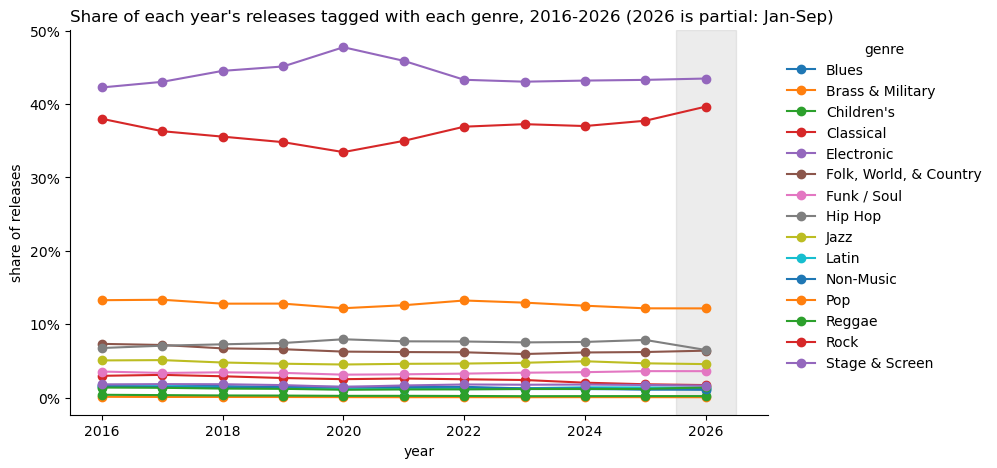

In [6]:
genre_shares = (
    trends.tag_shares_by_year(main["release_genres"], tag_col="genre").toPandas().sort_values(["genre", "year"])
)
ax = viz.plot_lines(genre_shares, "year", "share", "genre",
                    title="Share of each year's releases tagged with each genre, 2016-2026 (2026 is partial: Jan-Sep)",
                    ylabel="share of releases", percent=True)
mark_partial(ax)
viz.save_figure(ax.figure, "rq1_genre_shares")
export.export_table(genre_shares, "rq1_genre_shares")
genre_shares[genre_shares.year.isin([config.YEAR_MIN, config.LAST_FULL_YEAR])].pivot(index="genre", columns="year", values="share")

In [7]:
START_YEAR, END_YEAR = config.YEAR_MIN, config.LAST_FULL_YEAR   # 2026 is partial, so the last full year ends the comparison
style_shares = trends.tag_shares_by_year(main["release_styles"], tag_col="style").cache()
style_movers = trends.top_movers(style_shares, start_year=START_YEAR, end_year=END_YEAR, min_releases=500).toPandas()
export.export_table(style_movers.assign(start_year=START_YEAR, end_year=END_YEAR), "rq1_style_movers")
pd.concat([style_movers.head(15), style_movers.tail(15)])   # 15 largest gains, then 15 largest losses

,style,share_start,n_start,share_end,n_end,change
0,Hardcore,0.040042,13604,0.051106,12991,0.011064
1,Alt-Pop,0.000409,139,0.010291,2616,0.009882
2,Black Metal,0.030346,10310,0.037503,9533,0.007156
3,Hardstyle,0.006225,2115,0.012022,3056,0.005797
4,Dungeon Synth,0.001507,512,0.006884,1750,0.005377
5,Dream Pop,0.001174,399,0.005893,1498,0.004719
6,Goregrind,0.001707,580,0.006393,1625,0.004686
7,Noise Rock,0.000430,146,0.004902,1246,0.004472
8,Indie Pop,0.019232,6534,0.023470,5966,0.004238
9,Alternative Metal,0.000386,131,0.004622,1175,0.004237


In [8]:
# Robustness: the same ranking without the releases of prolific artist-years (>= config.PROLIFIC_ARTIST_MIN_PER_YEAR in one year).
prolific = trends.prolific_artist_years(main["release_artists"]).cache()
styles_clean = trends.drop_prolific_releases(main["release_styles"], main["release_artists"], prolific)
movers_clean = trends.top_movers(
    trends.tag_shares_by_year(styles_clean, tag_col="style"),
    start_year=START_YEAR, end_year=END_YEAR, min_releases=500,
).toPandas()

change_main = style_movers.set_index("style")["change"]
change_clean = movers_clean.set_index("style")["change"]
spearman = change_main.corr(change_clean, method="spearman")   # aligned on style
print(f"Spearman correlation of the style change, all releases vs without prolific artists: {spearman:.3f} "
      f"({len(change_main.index.intersection(change_clean.index))} styles in both)")

shown = pd.unique(pd.concat([style_movers.head(15), style_movers.tail(15), movers_clean.head(15), movers_clean.tail(15)])["style"])
movers_no_prolific = pd.DataFrame({"style": shown})
movers_no_prolific["change_main"] = movers_no_prolific["style"].map(change_main)
movers_no_prolific["change_no_prolific"] = movers_no_prolific["style"].map(change_clean)
movers_no_prolific["shrunk_by"] = movers_no_prolific["change_main"].abs() - movers_no_prolific["change_no_prolific"].abs()
movers_no_prolific["spearman_all_styles"] = spearman
movers_no_prolific = movers_no_prolific.sort_values("change_no_prolific", ascending=False)
export.export_table(movers_no_prolific, "rq1_movers_no_prolific")
display(prolific.toPandas())                                              # the prolific artist-years themselves
movers_no_prolific.sort_values("shrunk_by", ascending=False).head(10)     # styles that lose most of their change

Spearman correlation of the style change, all releases vs without prolific artists: 0.995 (226 styles in both)


,artist_id,artist_name,year,n_releases
0,6351861,This Is What I Hear When You Talk,2019,1233
1,6391827,Nosferatu 1922,2018,962
2,6351861,THIS IS WHAT I HEAR WHEN YOU TALK,2023,958
3,4607669,Merzlux,2024,906
4,6391827,Nosferatu 1922,2019,799
5,6351861,This Is What I Hear When You Talk,2024,547
6,1378165,Saito Koji,2022,524
7,15273480,Fuck My Corpse Forever,2024,500
8,211586,Tole Ache,2022,499
9,2532180,King Gizzard And The Lizard Wizard,2021,496


,style,change_main,change_no_prolific,shrunk_by,spearman_all_styles
10,Progressive House,0.004076,0.003068,0.001008,0.995491
19,Pop Rock,-0.005333,-0.004874,0.000459,0.995491
21,Punk,-0.005466,-0.005463,0.000003,0.995491
24,Vocal,-0.006242,-0.006245,-0.000003,0.995491
23,Downtempo,-0.006137,-0.006141,-0.000004,0.995491
16,Electro,-0.005090,-0.005098,-0.000008,0.995491
26,Abstract,-0.006391,-0.006404,-0.000012,0.995491
15,Progressive Trance,-0.004727,-0.004746,-0.000019,0.995491
12,Hard Techno,0.003854,0.003874,-0.000020,0.995491
17,Vaporwave,-0.005123,-0.005144,-0.000021,0.995491


> **Finding.** At genre level the decade is stable: Electronic (42.3% of releases in 2016, 43.3% in 2025) and Rock (38.0%, 37.7%) stay on top, Hip Hop gains most (6.8% to 7.9%), and Pop (13.3% to 12.2%), Folk, World, & Country (7.3% to 6.2%) and Classical (3.0% to 1.8%) lose ground. The movement is at style level. The largest gains are Hardcore (4.0% to 5.1%), Alt-Pop (from 139 releases to 2,616, or 0.04% to 1.03%), Black Metal (3.0% to 3.8%), Hardstyle (0.6% to 1.2%) and Dungeon Synth; the largest losses are Experimental (8.3% to 6.9%), Electro House (1.5% to 0.5%), House (5.6% to 4.9%), Abstract and Noise. Dropping the 35 prolific artist-years barely changes this ranking (Spearman correlation 0.995 over 226 styles), and only Progressive House loses a visible part of its gain (+0.41 to +0.31 percentage points). Two cautions apply: the Discogs style "Hardcore" covers both hardcore punk and hardcore techno, and Classical, which loses about two-fifths of its share, is also the slowest genre to be catalogued (5.4).

,year,entropy,evenness,entropy_base_tags,n_new_tags,new_tag_pair_share
0,2016,7.318521,0.771685,7.318521,0,0.000000
1,2017,7.334711,0.773228,7.334141,18,0.000046
2,2018,7.335712,0.771869,7.334924,22,0.000065
3,2019,7.331814,0.772269,7.330782,21,0.000092
4,2020,7.300678,0.768666,7.298833,21,0.000232
5,2021,7.353934,0.775749,7.352079,19,0.000230
6,2022,7.381598,0.777513,7.379303,22,0.000284
7,2023,7.437936,0.782789,7.434684,24,0.000498
8,2024,7.456988,0.786788,7.453531,18,0.000526
9,2025,7.466649,0.785155,7.462535,29,0.000505


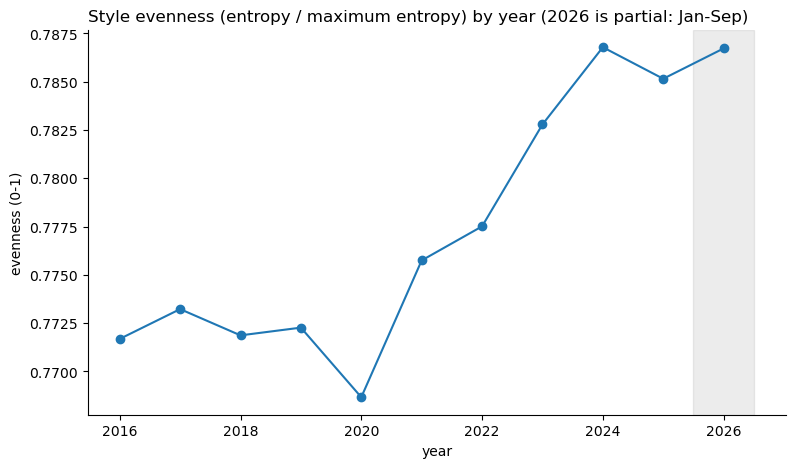

In [9]:
entropy = (
    trends.entropy_decomposition(main["release_styles"], tag_col="style", base_year=config.YEAR_MIN)
    .toPandas().sort_values("year")
)
ax = viz.plot_lines(entropy, "year", "evenness", title="Style evenness (entropy / maximum entropy) by year (2026 is partial: Jan-Sep)",
                    ylabel="evenness (0-1)")
mark_partial(ax)
viz.save_figure(ax.figure, "rq1_style_evenness")
export.export_table(entropy, "rq1_entropy")
entropy

PosixPath('/home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/figures/rq1_style_entropy_decomposition.png')

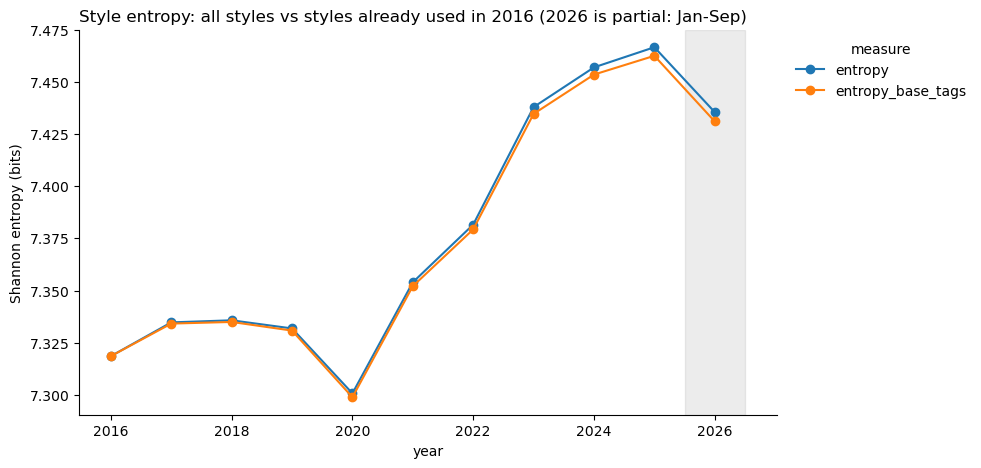

In [10]:
# Is the change new styles appearing, or evener use of the styles that already existed in the base year?
bits = entropy.melt(id_vars="year", value_vars=["entropy", "entropy_base_tags"], var_name="measure", value_name="bits")
ax = viz.plot_lines(bits, "year", "bits", "measure",
                    title=f"Style entropy: all styles vs styles already used in {config.YEAR_MIN} (2026 is partial: Jan-Sep)",
                    ylabel="Shannon entropy (bits)")
mark_partial(ax)
viz.save_figure(ax.figure, "rq1_style_entropy_decomposition")

[entropy_sensitivity] 348.3 s


,year,evenness_full,evenness_sub_mean,evenness_sub_min,evenness_sub_max
0,2016,0.771685,0.773007,0.772196,0.773757
1,2017,0.773228,0.774393,0.774041,0.774991
2,2018,0.771869,0.773566,0.773204,0.774114
3,2019,0.772269,0.774180,0.773804,0.774740
4,2020,0.768666,0.770555,0.769836,0.771290
5,2021,0.775749,0.776803,0.775982,0.777618
6,2022,0.777513,0.778471,0.778059,0.779017
7,2023,0.782789,0.783600,0.783077,0.784160
8,2024,0.786788,0.787021,0.786914,0.787216
9,2025,0.785155,0.785155,0.785155,0.785155


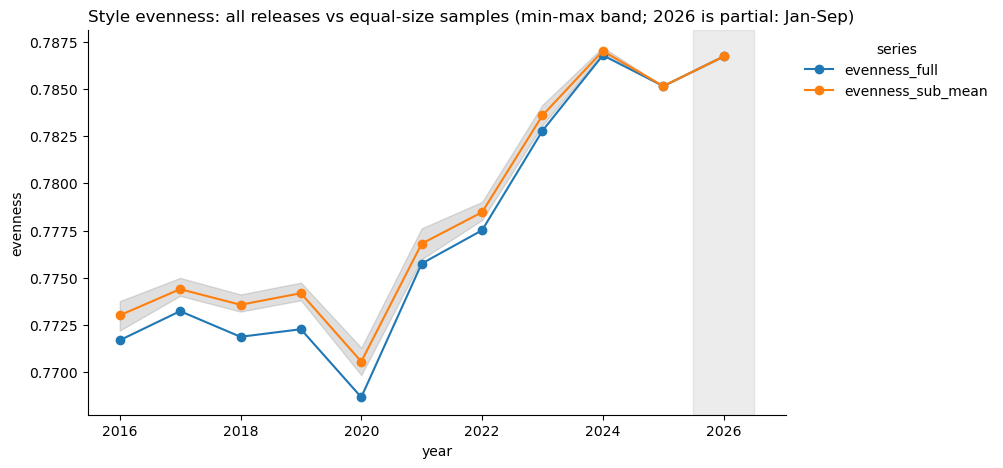

In [11]:
# Does evenness depend on how many releases a year has? Equal-size random samples per year (about 6-8 min on the full data).
with clustering.timed("entropy_sensitivity"):
    sensitivity = (
        trends.entropy_sensitivity(main["release_styles"], main["releases"], tag_col="style", n_draws=5, seed=42)
        .toPandas().sort_values("year")
    )
lines = sensitivity.melt(id_vars="year", value_vars=["evenness_full", "evenness_sub_mean"], var_name="series", value_name="evenness")
ax = viz.plot_lines(lines, "year", "evenness", "series",
                    title="Style evenness: all releases vs equal-size samples (min-max band; 2026 is partial: Jan-Sep)")
ax.fill_between(sensitivity["year"], sensitivity["evenness_sub_min"], sensitivity["evenness_sub_max"], alpha=0.25, color="grey")
mark_partial(ax)
viz.save_figure(ax.figure, "rq1_entropy_sensitivity")
export.export_table(sensitivity, "rq1_entropy_sensitivity")
sensitivity

,year,n_nodes,n_edges,density,n_components,largest_component_share,modularity
0,2016,298,2048,0.046279,2,0.989933,0.637724
1,2017,303,2042,0.044631,3,0.980198,0.652246
2,2018,299,2030,0.045566,2,0.993311,0.645559
3,2019,294,1989,0.046180,3,0.986395,0.630348
4,2020,303,2132,0.046598,2,0.993399,0.620486
5,2021,310,2096,0.043762,2,0.993548,0.627427
6,2022,311,1943,0.040307,2,0.993569,0.624942
7,2023,321,1845,0.035923,2,0.993769,0.657754
8,2024,306,1670,0.035787,3,0.986928,0.665157
9,2025,300,1530,0.034114,5,0.973333,0.675890


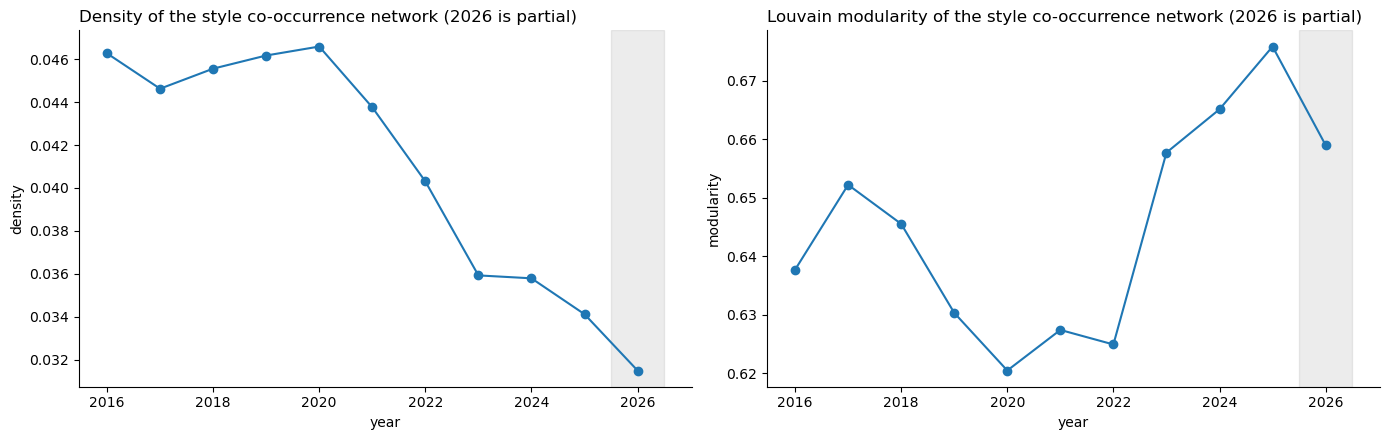

In [12]:
cooccurrence = trends.style_cooccurrence(main["release_styles"], min_count=50).cache()
style_network = trends.cooccurrence_graph_stats(cooccurrence)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
viz.plot_lines(style_network, "year", "density", title="Density of the style co-occurrence network (2026 is partial)", ax=axes[0])
viz.plot_lines(style_network, "year", "modularity", title="Louvain modularity of the style co-occurrence network (2026 is partial)", ax=axes[1])
for ax in axes:
    mark_partial(ax)
fig.tight_layout()
viz.save_figure(fig, "rq1_style_network")
export.export_table(style_network, "rq1_style_network")
style_network

In [13]:
# The strongest style pairs in the last full year (Jaccard index of the two styles' release sets).
cooccurrence.where(F.col("year") == config.LAST_FULL_YEAR).orderBy(F.desc("jaccard")).limit(15).toPandas()

,year,style_a,style_b,n_both,n_a,n_b,jaccard
0,2025,Health-Fitness,Therapy,54,68,84,0.551020
1,2025,Health-Fitness,Special Effects,60,68,115,0.487805
2,2025,Bollywood,Hindustani,54,108,78,0.409091
3,2025,Special Effects,Therapy,56,115,84,0.391608
4,2025,Footwork,Juke,66,178,98,0.314286
5,2025,Score,Soundtrack,912,1236,3057,0.269743
6,2025,Orchestra,Symphony,89,321,143,0.237333
7,2025,Concerto,Orchestra,93,185,321,0.225182
8,2025,Chamber Music,String Ensemble,73,268,138,0.219219
9,2025,Concerto,String Instrument,66,185,188,0.214984


> **Finding.** Slightly, and mostly since 2020. Style evenness (Shannon entropy divided by its maximum; Pielou 1966) is 0.772 in 2016, stays between 0.769 and 0.773 until 2020, then climbs to 0.785 in 2025, while entropy goes from 7.32 to 7.47 bits. Nearly all of the rise comes from evener use of styles that already existed in 2016: entropy over those styles alone reaches 7.46 bits in 2025, and styles new since 2016 carry only 0.05% of style tags. Equal-size random samples follow the same path (0.773 to 0.785), so the rise is not an effect of the smaller recent years. The co-occurrence networks add that styles are combined less: style pairs with at least 50 shared releases fall from 2,048 in 2016 to 1,530 in 2025 and modularity rises from 0.638 to 0.676, although part of the edge loss is mechanical because 2025 has 27% fewer catalogued releases than 2016 and the threshold is absolute.

### 5.2 RQ2 - Format mix and the vinyl boom

*How did the format mix change, and how much of the vinyl boom was reissues rather than new music?*

Exploration and parameter choices: [`explorers/03_formats_and_reissues.ipynb`](explorers/03_formats_and_reissues.ipynb). Functions: `vinyl.formats`.

Main formats, largest mean share first: ['File', 'Vinyl', 'CD', 'Cassette', 'CDr', 'All Media', 'DVD']


format_name,All Media,CD,CDr,Cassette,DVD,File,Other,Vinyl
year,,,,,,,,
2016,0.010,0.278,0.066,0.060,0.011,0.396,0.018,0.191
2017,0.009,0.259,0.058,0.062,0.009,0.413,0.017,0.200
2018,0.009,0.229,0.050,0.064,0.007,0.439,0.017,0.211
2019,0.010,0.204,0.046,0.063,0.006,0.459,0.017,0.220
2020,0.010,0.159,0.038,0.067,0.004,0.518,0.017,0.209
2021,0.009,0.165,0.036,0.075,0.004,0.478,0.019,0.239
2022,0.008,0.167,0.037,0.072,0.003,0.449,0.019,0.268
2023,0.008,0.156,0.038,0.068,0.002,0.436,0.019,0.295
2024,0.008,0.154,0.038,0.068,0.002,0.426,0.019,0.305


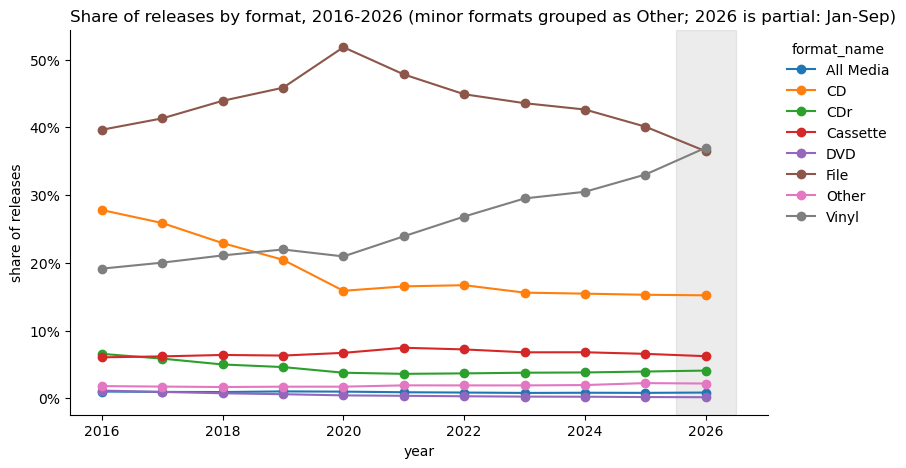

In [14]:
format_shares = formats.format_shares_by_year(main["release_formats"]).toPandas()
main_format_names = formats.main_formats(format_shares, min_share=0.01)   # >= 1% of releases in at least one full year
grouped_format_shares = (
    formats.format_shares_by_year(formats.group_minor_formats(main["release_formats"], main_format_names))
    .toPandas().sort_values(["format_name", "year"])
)
ax = viz.plot_lines(grouped_format_shares, "year", "share", "format_name",
                    title="Share of releases by format, 2016-2026 (minor formats grouped as Other; 2026 is partial: Jan-Sep)",
                    ylabel="share of releases", percent=True)
mark_partial(ax)
viz.save_figure(ax.figure, "rq2_format_shares")
export.export_table(grouped_format_shares, "rq2_format_shares")
print("Main formats, largest mean share first:", main_format_names)
grouped_format_shares.pivot(index="year", columns="format_name", values="share").round(3)

> **Finding.** Vinyl's share of releases rises in every year but 2020, from 19.1% in 2016 to 33.0% in 2025, and reaches 37.0% in the partial 2026. CD falls from 27.8% to 15.3%, most of it before 2021 (15.9% in 2020), and is flat after that. Digital files (File) stay the largest single format until 2025 but peak at 51.8% in 2020 and fall back to 40.1%; in the partial 2026 vinyl is ahead of File for the first time (37.0% against 36.5%). Cassette edges up from 6.0% to a high of 7.5% in 2021 and settles at 6.6%, while CDr falls from 6.6% to 3.9%. The recent File figures are the least secure, since in the 2020 comparison only 45.4% of File releases were catalogued by the end of their release year against 77.5% of vinyl ones (5.4), so the late crossover of vinyl and File is partly a cataloguing effect.

flag,is_reissue,is_reissue_any,is_reissue_master
year,,,
2016,0.203,0.290,0.269
2017,0.201,0.286,0.265
2018,0.205,0.292,0.270
2019,0.198,0.288,0.267
2020,0.210,0.302,0.279
2021,0.240,0.355,0.333
2022,0.254,0.385,0.365
2023,0.256,0.384,0.364
2024,0.226,0.336,0.315


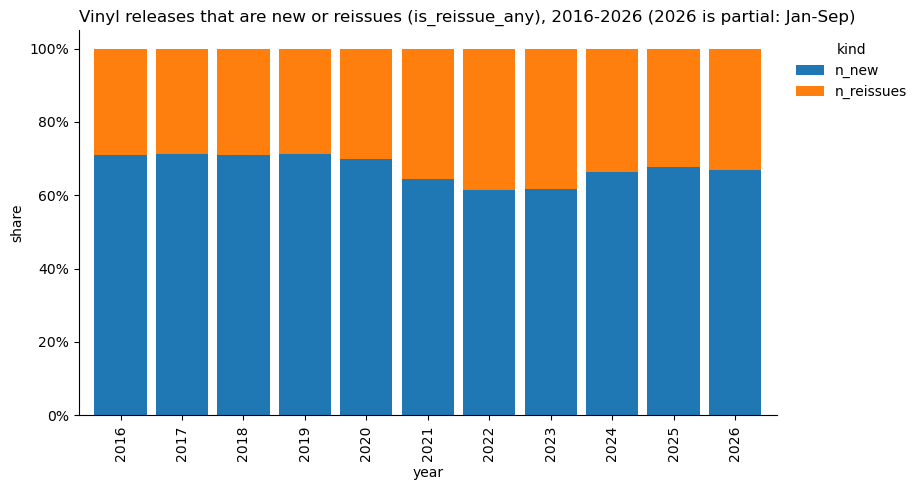

In [15]:
flagged = formats.add_master_reissue_flag(main["release_formats"], main["releases"], main["masters"], min_gap_years=1)
REISSUE_FLAG = "is_reissue_any"   # the broadest definition (reissue tag or older master), reported alongside the other two
REISSUE_FLAGS = ["is_reissue", "is_reissue_master", REISSUE_FLAG]

vinyl_releases = flagged.where(F.col("format_name") == "Vinyl")
by_flag = reduce(
    lambda a, b: a.unionByName(b),
    [formats.reissue_share(vinyl_releases, by=["year"], flag_col=f).withColumn("flag", F.lit(f)) for f in REISSUE_FLAGS],
).cache()
vinyl_reissues = by_flag.toPandas().sort_values(["flag", "year"])

long = (vinyl_reissues[vinyl_reissues.flag == REISSUE_FLAG]
        .melt(id_vars="year", value_vars=["n_new", "n_reissues"], var_name="kind", value_name="n"))
ax = viz.plot_stacked_share(long, "year", "n", "kind",
                            title=f"Vinyl releases that are new or reissues ({REISSUE_FLAG}), 2016-2026 (2026 is partial: Jan-Sep)")
viz.save_figure(ax.figure, "rq2_vinyl_reissue_share")
export.export_table(vinyl_reissues, "rq2_vinyl_reissues")
vinyl_reissues.pivot(index="year", columns="flag", values="reissue_share").round(3)

In [16]:
# Share of the growth in vinyl releases (first year to last full year) that is reissues, for each definition.
growth = (
    formats.growth_explained_by_reissues(by_flag, config.YEAR_MIN, config.LAST_FULL_YEAR)
    .toPandas().sort_values("flag").assign(start_year=config.YEAR_MIN, end_year=config.LAST_FULL_YEAR)
)
export.export_table(growth, "rq2_growth_explained")
growth

,flag,releases_start,releases_end,reissues_start,reissues_end,growth_explained,start_year,end_year
2,is_reissue,73730,92779,14973,20187,0.273715,2016,2025
0,is_reissue_any,73730,92779,21353,29936,0.450575,2016,2025
1,is_reissue_master,73730,92779,19803,27940,0.427162,2016,2025


,year,genre,n_releases,n_reissues,n_new,reissue_share
144,2025,Rock,49520,18225,31295,0.368033
131,2025,Electronic,23101,5290,17811,0.228994
163,2025,Pop,12731,4112,8619,0.322991
21,2025,Hip Hop,7394,2413,4981,0.326346
9,2025,"Folk, World, & Country",7148,1865,5283,0.260912
54,2025,Funk / Soul,5734,1811,3923,0.315835
105,2025,Jazz,5618,1936,3682,0.344607
134,2025,Stage & Screen,2435,1084,1351,0.445175
51,2025,Reggae,2195,746,1449,0.339863
45,2025,Latin,1752,754,998,0.430365


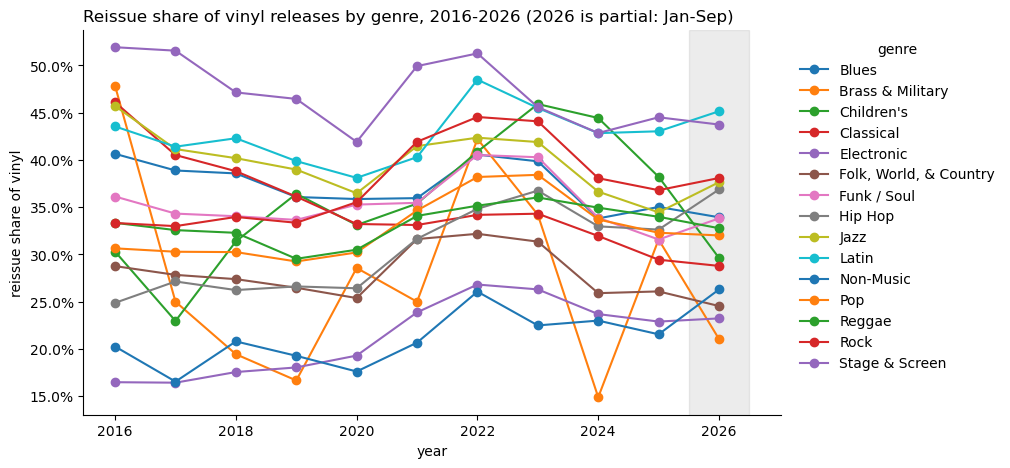

In [17]:
by_genre = (
    formats.reissue_share(
        vinyl_releases.join(main["release_genres"].select("release_id", "genre"), "release_id"),
        by=["year", "genre"], flag_col=REISSUE_FLAG,
    ).toPandas().sort_values(["genre", "year"])
)
ax = viz.plot_lines(by_genre, "year", "reissue_share", "genre",
                    title="Reissue share of vinyl releases by genre, 2016-2026 (2026 is partial: Jan-Sep)",
                    ylabel="reissue share of vinyl", percent=True)
mark_partial(ax)
viz.save_figure(ax.figure, "rq2_vinyl_reissue_by_genre")
export.export_table(by_genre, "rq2_reissue_by_genre")
by_genre[by_genre.year == config.LAST_FULL_YEAR].sort_values("n_releases", ascending=False)

Distinct releases whose master is dated after the release (left out): {'Vinyl': 3749, 'CD': 2571}


/home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/vinyl/viz.py:116: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = data.pivot_table(index=x, columns=series, values=y, aggfunc="sum").fillna(0)


/home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/vinyl/viz.py:116: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = data.pivot_table(index=x, columns=series, values=y, aggfunc="sum").fillna(0)


format_name,CD,Vinyl
year,,
2016,24,18
2017,24,19
2018,25,18
2019,23,17
2020,23,18
2021,24,16
2022,24,15
2023,25,17
2024,26,20


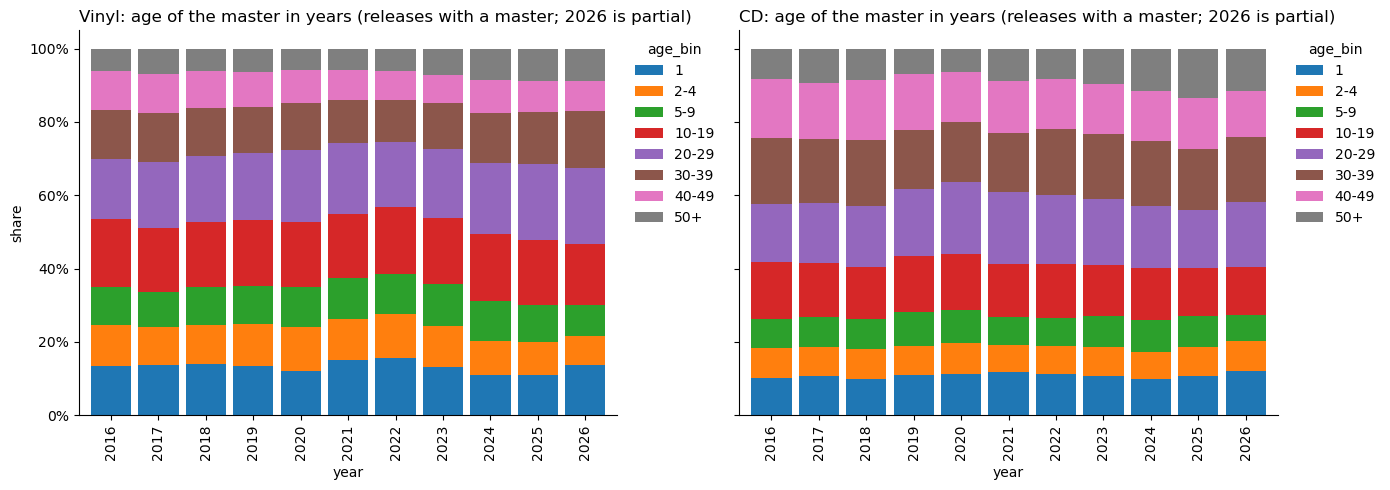

In [18]:
# How old is the music on releases that have a master? Age = release year - master year (at least 1).
AGE_FORMATS = ["Vinyl", "CD"]
reissue_age = pd.concat(
    [formats.reissue_age_distribution(flagged, fmt).toPandas().assign(format_name=fmt) for fmt in AGE_FORMATS],
    ignore_index=True,
).sort_values(["format_name", "year", "age_bin_order"])
print("Distinct releases whose master is dated after the release (left out):",
      {fmt: formats.count_master_after_release(flagged, fmt) for fmt in AGE_FORMATS})

age_labels = formats.age_bin_labels()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, fmt in zip(axes, AGE_FORMATS):
    part = reissue_age[reissue_age.format_name == fmt]
    part = part.assign(age_bin=pd.Categorical(part["age_bin"], categories=age_labels, ordered=True))
    viz.plot_stacked_share(part, "year", "n_releases", "age_bin",
                           title=f"{fmt}: age of the master in years (releases with a master; 2026 is partial)", ax=ax)
fig.tight_layout()
viz.save_figure(fig, "rq2_reissue_age")
export.export_table(reissue_age, "rq2_reissue_age")
reissue_age.groupby(["format_name", "year"])["median_age"].first().unstack("format_name")

,year,n_format,n_with_role,coverage
7,2016,73730,16866,0.228754
9,2017,78156,17795,0.227686
1,2018,83660,18266,0.218336
5,2019,86550,18900,0.218371
6,2020,87042,19025,0.218573
10,2021,93575,18330,0.195886
3,2022,96821,19974,0.206298
2,2023,102399,18915,0.184719
8,2024,95178,15911,0.167171
0,2025,92779,12084,0.130245


,rank,company_id,company_name,total_full_years
36,1,430654,GZ Media,60766
2,2,313190,Optimal Media GmbH,20556
45,3,56025,MPO,16574
0,4,267164,Record Industry,12161
15,5,271440,Schallplattenfabrik Pallas GmbH,6031
5,6,523699,Precision Record Pressing,3704
7,7,178173,Zenith Records (2),3261
25,8,321797,Gotta Groove Records,3113
1,9,66254,Record Technology Incorporated,2677
34,10,833505,Memphis Record Pressing,2635


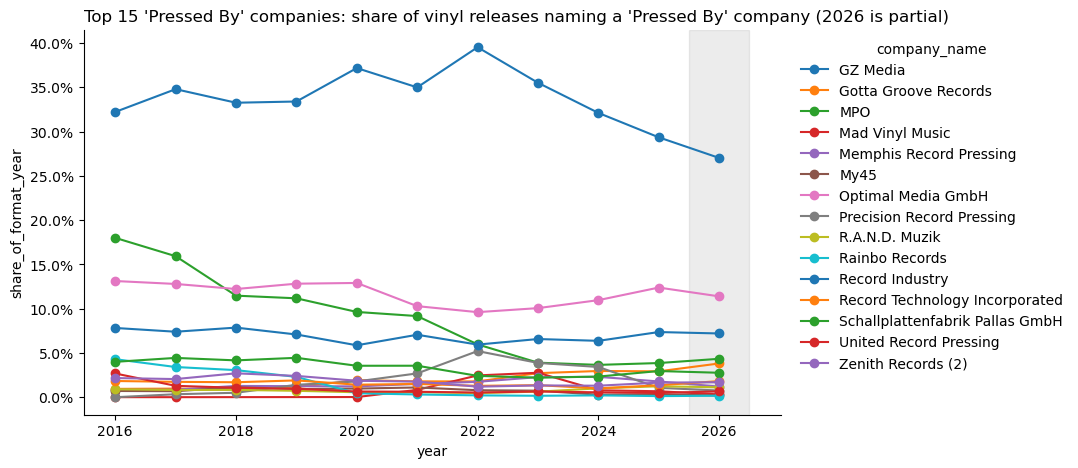

In [19]:
# Pressing plants: how many vinyl releases name a "Pressed By" company at all, and which companies carry the most.
PRESSING_ROLE = "Pressed By"
plant_coverage = formats.pressing_plant_coverage(main["release_companies"], main["release_formats"], "Vinyl", PRESSING_ROLE).toPandas()
top_plants = formats.top_pressing_plants(main["release_companies"], main["release_formats"], "Vinyl", PRESSING_ROLE, top_n=15).toPandas()

ax = viz.plot_lines(top_plants, "year", "share_of_format_year", "company_name",
                    title=f"Top 15 '{PRESSING_ROLE}' companies: share of vinyl releases naming a '{PRESSING_ROLE}' company (2026 is partial)",
                    percent=True)
mark_partial(ax)
viz.save_figure(ax.figure, "rq2_pressing_plants")

pressing_plants = (
    plant_coverage.merge(top_plants.drop(columns="n_year_with_role"), on="year", how="left")
    .sort_values(["year", "rank"])
)
export.export_table(pressing_plants, "rq2_pressing_plants")
display(plant_coverage.sort_values("year"))
top_plants.drop_duplicates("company_id").sort_values("rank")[["rank", "company_id", "company_name", "total_full_years"]]

> **Finding.** With the broad definition (`is_reissue_any`), 29.0% of vinyl releases in 2016 were reissues; the share peaks at 38.5% in 2022 and is 32.3% in 2025. Vinyl releases grew from 73,730 in 2016 to 92,779 in 2025 and reissues explain 45.1% of that growth (27.4% with tags only, 42.7% with masters only), so new music accounts for more than half of the boom on every definition. Rock dominates in absolute terms, with 18,225 reissues among its 49,520 vinyl releases of 2025 (36.8%), while Electronic, the second largest vinyl genre, has the lowest share among the big genres (22.9%) and Stage & Screen (44.5%) and Latin (43.0%) the highest. The reissued music is getting older again: the median age of the master on vinyl reissues falls from 18 years in 2016 to 15 in 2022 and rises to 20 in 2025, while on CD it stays between 23 and 26. Only 13.0% of 2025 vinyl releases name a "Pressed By" company (22.9% in 2016), so the plant ranking, led by GZ Media with 60,766 releases in 2016-2025, describes a shrinking subset.

### 5.3 RQ3 - Label power

*How concentrated is release activity within the three majors' label trees, and which artists, producers, and writers dominate each label's output?*

Exploration and parameter choices: [`explorers/04_labels_and_majors.ipynb`](explorers/04_labels_and_majors.ipynb). Functions: `vinyl.labels`.

In [20]:
# Resolve every label to its root once and reuse it everywhere below: the walk over 2.4 M labels is slow.
with clustering.timed("resolve_label_roots"):
    label_roots = labels.resolve_label_roots(main["labels"]).cache()
    label_roots.count()   # fills the cache
tagged_labels = labels.tag_major_labels(label_roots).cache()   # matches config.MAJOR_ROOT_IDS
tagged_labels.groupBy("major").agg(F.count("*").alias("n_labels")).toPandas()

[resolve_label_roots] 392.1 s


,major,n_labels
0,Independent,2411275
1,Sony,3633
2,Universal,8080
3,Warner,3087


,year,major,n_releases,n_year,share
16,2016,Independent,357853,385281,0.928810
42,2025,Independent,266506,280882,0.948818
33,2016,Sony,11622,385281,0.030165
7,2025,Sony,5297,280882,0.018858
25,2016,Universal,14580,385281,0.037843
36,2025,Universal,8875,280882,0.031597
32,2016,Warner,7507,385281,0.019484
5,2025,Warner,4869,280882,0.017335


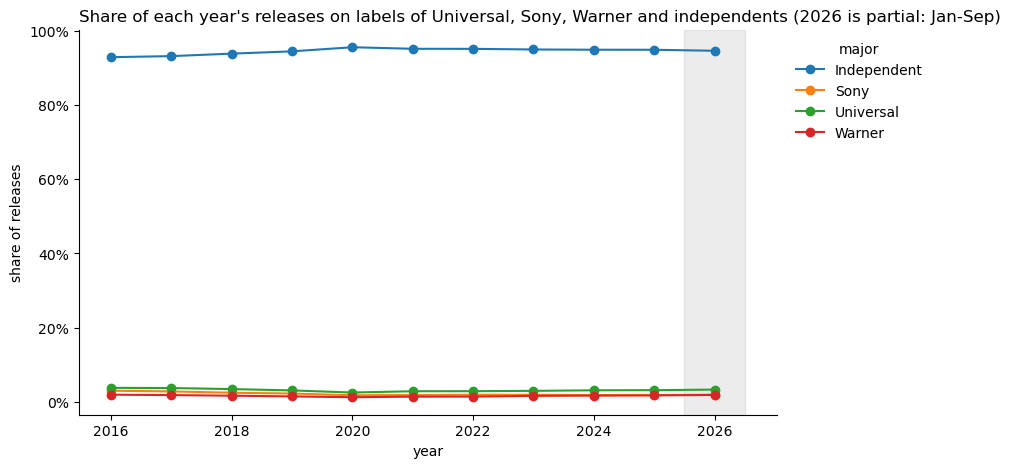

In [21]:
major_share = labels.major_share_by_year(main["release_labels"], tagged_labels).toPandas().sort_values(["major", "year"])
ax = viz.plot_lines(major_share, "year", "share", "major",
                    title="Share of each year's releases on labels of Universal, Sony, Warner and independents (2026 is partial: Jan-Sep)",
                    ylabel="share of releases", percent=True)
mark_partial(ax)
viz.save_figure(ax.figure, "rq3_major_share")
export.export_table(major_share, "rq3_major_share")
major_share[major_share.year.isin([config.YEAR_MIN, config.LAST_FULL_YEAR])]

> **Finding.** The majors' trees hold a small and shrinking share of what gets catalogued. Universal falls from 3.8% of each year's releases in 2016 to 3.2% in 2025, Sony from 3.0% to 1.9% (11,622 to 5,297 releases) and Warner from 1.9% to 1.7%, while labels outside the three trees rise from 92.9% to 94.9%. Together the majors carry at most 8.7% of releases in 2016 and 6.8% in 2025; this is an upper bound, because a release on labels of two groups counts in both. The trees come from the October 2026 labels table for every year, so the decline reflects release activity, or what contributors catalogue, and not ownership changes. It is also a lower bound on the majors' reach, since 44.7% of 2025 releases sit only on labels with neither a parent nor children in Discogs (parent coverage table above), and some of those labels do belong to a major.

In [22]:
# Concentration inside single labels: median HHI and median share of the top artist, by major.
real_artists = main["release_artists"].where(~F.col("artist_id").isin(list(networks.PLACEHOLDER_ARTIST_IDS)))   # drop "Various", "Unknown Artist"
concentration = labels.artist_concentration(main["release_labels"], real_artists, min_releases=50)
(concentration.join(tagged_labels.select("label_id", "major"), "label_id")
    .groupBy("major")
    .agg(F.count("*").alias("n_labels"),
         F.expr("percentile_approx(hhi, 0.5)").alias("median_hhi"),
         F.expr("percentile_approx(top_artist_share, 0.5)").alias("median_top_artist_share"))
    .toPandas())

,major,n_labels,median_hhi,median_top_artist_share
0,Sony,178,0.035435,0.137255
1,Warner,156,0.031338,0.118421
2,Universal,267,0.036306,0.136364
3,Independent,15124,0.046307,0.136319


,major,n_pairs,n_artists,top_artist_id,top_artist_name,top_artist_share,hhi,scope,year
3,Independent,4068511,897929,6351861,THIS IS WHAT I HEAR WHEN YOU TALK,0.000839,0.000014,overall,<NA>
0,Sony,96543,18484,45467,Pink Floyd,0.006546,0.000508,overall,<NA>
1,Universal,143478,22047,20991,The Rolling Stones,0.006092,0.000501,overall,<NA>
2,Warner,75328,13751,10263,David Bowie,0.007899,0.000751,overall,<NA>
38,Independent,395455,188063,10263,David Bowie,0.000895,0.000022,year,2016
45,Independent,303948,134625,15661965,U.A. (3),0.001540,0.000035,year,2025
6,Sony,13731,5288,45467,Pink Floyd,0.015512,0.000919,year,2016
22,Sony,5779,2075,45467,Pink Floyd,0.012459,0.001564,year,2025
46,Universal,16869,5292,20991,The Rolling Stones,0.007647,0.000783,year,2016
36,Universal,10316,3289,2171152,The Weeknd,0.007367,0.001139,year,2025


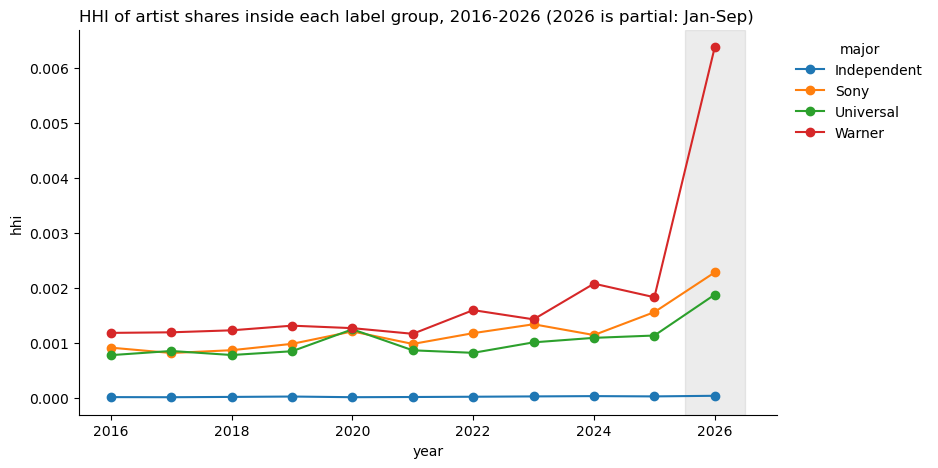

In [23]:
# Concentration of each whole label group (a major's tree, or the independents), overall and by year.
group_overall = labels.group_concentration(
    main["release_labels"], real_artists, tagged_labels, group_col="major", min_releases=50
).toPandas().assign(scope="overall")
group_by_year = labels.group_concentration(
    main["release_labels"], real_artists, tagged_labels, group_col="major", min_releases=50, by_year=True
).toPandas().assign(scope="year")
group_conc = (
    pd.concat([group_overall, group_by_year], ignore_index=True)
    .astype({"year": "Int64"}).sort_values(["scope", "major", "year"])
)
export.export_table(group_conc, "rq3_group_concentration")

ax = viz.plot_lines(group_by_year.sort_values(["major", "year"]), "year", "hhi", "major",
                    title="HHI of artist shares inside each label group, 2016-2026 (2026 is partial: Jan-Sep)")
mark_partial(ax)
viz.save_figure(ax.figure, "rq3_group_hhi")
group_conc[(group_conc.scope == "overall") | group_conc.year.isin([config.YEAR_MIN, config.LAST_FULL_YEAR])]

In [24]:
# How much parent information do the labels of each year's releases have? Self-released placeholders get their own class.
# Keep the 312,527 self-released ids as a DataFrame; passing them as a Python list is extremely slow.
self_released = labels.self_released_label_ids(main["labels"]).cache()
parent_cov = labels.parent_coverage(main["release_labels"], tagged_labels, self_released=self_released).toPandas()
export.export_table(parent_cov, "rq3_parent_coverage")
parent_cov

,year,on_root_alone,in_tree,self_released,unknown_label,n_releases,share_on_root_alone,share_in_tree,share_self_released,share_unknown_label
0,2016,144675,175989,64557,60,385281,0.375505,0.456781,0.167558,0.000156
1,2017,148978,179375,61930,72,390355,0.381647,0.459518,0.158650,0.000184
2,2018,153303,178632,64718,57,396710,0.386436,0.450284,0.163137,0.000144
3,2019,156630,173627,63659,100,394016,0.397522,0.440660,0.161565,0.000254
4,2020,170877,169965,74710,119,415671,0.411087,0.408893,0.179733,0.000286
5,2021,163613,164460,63097,127,391297,0.418130,0.420295,0.161251,0.000325
6,2022,150944,154102,55663,154,360863,0.418286,0.427037,0.154250,0.000427
7,2023,146946,151141,48759,219,347065,0.423396,0.435483,0.140490,0.000631
8,2024,133913,135411,42456,399,312179,0.428962,0.433761,0.135999,0.001278
9,2025,125589,119105,35973,215,280882,0.447124,0.424039,0.128072,0.000765


In [25]:
# Releases with a writer credit at the release level and at the track level.
writer_levels = labels.credit_level_coverage(main["release_credits"], config.WRITING_ROLES).toPandas().sort_values(["year", "level"])
export.export_table(writer_levels, "rq3_writer_levels")
writer_levels.pivot(index="year", columns="level", values="n_releases")

level,any,release,track
year,,,
2016,99385,69008,38018
2017,101888,70107,38730
2018,101650,71167,37427
2019,101492,71370,36597
2020,108506,78689,36396
2021,105312,75294,36351
2022,98733,70995,33886
2023,92652,67495,30933
2024,82150,59071,27936


In [26]:
# Top 5 producers/engineers and writers for a fixed set of flagship labels (ids checked against the 2026 labels table).
FLAGSHIP_LABELS = {
    1866: "Columbia", 681: "Atlantic", 2311: "Interscope", 8377: "Island",
    4241: "Def Jam", 23528: "Warp Records", 77343: "Sub Pop", 26465: "Domino",
}
flagship_releases = main["release_labels"].where(F.col("label_id").isin(list(FLAGSHIP_LABELS)))   # filter first: far fewer joins
columns = ["label_id", "label_name", "rank", "artist_name", "n_releases", "share"]
top_producers = labels.top_contributors(flagship_releases, main["release_credits"], config.PRODUCTION_ROLES, top_n=5).toPandas()
top_writers = labels.top_contributors(flagship_releases, main["release_credits"], config.WRITING_ROLES, top_n=5).toPandas()
print("Producers and engineers")
display(top_producers.sort_values(["label_id", "rank"])[columns])
print("Writers")
display(top_writers.sort_values(["label_id", "rank"])[columns])

Producers and engineers


,label_id,label_name,rank,artist_name,n_releases,share
0,681,Atlantic,1,Serban Ghenea,265,0.062901
1,681,Atlantic,2,Chris Gehringer,220,0.052219
2,681,Atlantic,3,Manny Marroquin,217,0.051507
3,681,Atlantic,4,Tom Dowd,200,0.047472
4,681,Atlantic,5,Stuart Hawkes,200,0.047472
5,1866,Columbia,1,Bob Ludwig,318,0.046634
6,1866,Columbia,2,Ryan Smith (2),203,0.029770
7,1866,Columbia,3,Daniel Krieger,201,0.029476
8,1866,Columbia,4,Teo Macero,187,0.027423
9,1866,Columbia,5,Greg Calbi,172,0.025224


Writers


,label_id,label_name,rank,artist_name,n_releases,share
0,681,Atlantic,1,Ed Sheeran,118,0.033850
1,681,Atlantic,2,Phil Collins,90,0.025818
2,681,Atlantic,3,Bruno Mars,84,0.024096
3,681,Atlantic,4,Michael Pollack (5),83,0.023810
4,681,Atlantic,5,Rivers Cuomo,75,0.021515
5,1866,Columbia,1,Bob Dylan,351,0.057522
6,1866,Columbia,2,Traditional,180,0.029499
7,1866,Columbia,3,Miles Davis,158,0.025893
8,1866,Columbia,4,Martin L. Gore,145,0.023763
9,1866,Columbia,5,Bruce Springsteen,125,0.020485


> **Finding.** A single label is about as dominated by its top artist whoever owns it: among labels with at least 50 release-artist pairs, the median top-artist share is 13.6% in Universal's tree, 13.7% in Sony's, 11.8% in Warner's and 13.6% among independents, although independents have a higher median HHI (0.046 against 0.031-0.036), meaning their output sits with fewer artists. Whole trees are far less concentrated (HHI 0.0005 for Universal and Sony, 0.0008 for Warner), and their top artists are catalogue acts: Pink Floyd for Sony, The Rolling Stones for Universal and David Bowie for Warner over the decade, and Pink Floyd, The Weeknd and The Grateful Dead in 2025. Tree HHI rises in all three majors between 2016 and 2025 (Sony 0.0009 to 0.0016) as fewer artists appear on each tree's catalogued releases (Sony 5,288 to 2,075). At the eight flagship labels the most credited producers and engineers are often the same people across labels: Serban Ghenea tops both Atlantic (265 releases) and Interscope (291), and Chris Gehringer, Greg Calbi, Manny Marroquin and Matt Colton each rank in the top five at two labels, while Bob Ludwig tops Columbia (318) and Dr. Dre and Kanye West rank high at their own labels, Interscope and Def Jam. Writer credits follow each label's signature acts: Bob Dylan at Columbia (351 releases), Finneas O'Connell at Interscope, Kanye West at Def Jam (17.6% of its writer-credited releases), U2 at Island and Richard D. James at Warp.

### 5.4 Snapshot comparison

*How did ownership change between January 2020 and October 2026, and how undercounted are the most recent years?*

Exploration and parameter choices: [`explorers/05_snapshot_comparison.ipynb`](explorers/05_snapshot_comparison.ipynb). Functions: `vinyl.snapshots`.

In [27]:
# Cache the two labels tables: the root walks and parent chains below read them many times.
label_cols = ["label_id", "label_name", "parent_id", "parent_name"]
labels_old = base["labels"].select(*label_cols).cache()
labels_new = main["labels"].select(*label_cols).cache()

parent_changes = snapshots.label_parent_changes(labels_old, labels_new).cache()
parent_changes.groupBy("change").count().orderBy(F.desc("count")).toPandas()

,change,count
0,unchanged,1280637
1,new_label,1041069
2,gained_parent,98619
3,removed_label,76517
4,changed_parent,4232
5,lost_parent,1518


In [28]:
# Largest labels (by in-scope releases) whose parent changed.
volume = main["release_labels"].groupBy("label_id").agg(F.countDistinct("release_id").alias("n_releases"))
(parent_changes.where(F.col("change").isin("changed_parent", "gained_parent", "lost_parent"))
    .join(volume, "label_id").orderBy(F.desc("n_releases")).limit(20).toPandas())

,label_id,label_name,parent_id_old,parent_name_old,parent_id_new,parent_name_new,change,n_releases
0,1818,Not On Label,NaN,None,205754,Stolen Riff Records,gained_parent,187763
1,38404,Universal Music Group,NaN,None,212,None,gained_parent,11123
2,1003,BMG,353658.0,Bertelsmann AG,281003,BMG Rights Management GmbH,changed_parent,8374
3,8377,Island Records,38404.0,Universal Music Group,3774752,Republic Corps,changed_parent,6088
4,11499,Nuclear Blast,1154355.0,Nuclear Blast Tonträger Produktions- und Vertr...,222987,Nuclear Blast GmbH,changed_parent,5681
5,38017,Republic Records,38404.0,Universal Music Group,3774752,Republic Corps,changed_parent,5513
6,10956,Century Media,122707.0,Century Media Records,264083,Sony Music Entertainment Germany GmbH,changed_parent,4569
7,27889,Empire,NaN,None,1818679,"Empire Distribution, Records and Publishing Inc.",gained_parent,3176
8,39357,Mercury,8377.0,Island Records,3774752,Republic Corps,changed_parent,3142
9,1004,Cleopatra,41071.0,Cleopatra Records,787855,Cleopatra Records Inc.,changed_parent,3134


In [29]:
# Do the three major roots exist in both snapshots, with the same parent?
root_check = snapshots.major_root_check(labels_old, labels_new)
for r in root_check[~root_check.ok].itertuples():
    print(f"CHECK {r.major} (root {r.root_id}): in 2020={r.in_old}, in 2026={r.in_new}, "
          f"parent in 2020={r.parent_id_old}, parent in 2026={r.parent_id_new}")
root_check

CHECK Universal (root 38404): in 2020=True, in 2026=True, parent in 2020=<NA>, parent in 2026=212
CHECK Warner (root 2345): in 2020=True, in 2026=True, parent in 2020=<NA>, parent in 2026=212


,major,root_id,in_old,in_new,label_name_old,label_name_new,parent_id_old,parent_id_new,ok
0,Universal,38404,True,True,Universal Music Group,Universal Music Group,<NA>,212,False
1,Sony,353657,True,True,Sony Corporation,Sony Corporation,<NA>,<NA>,True
2,Warner,2345,True,True,Warner Music Group,Warner Music Group,<NA>,212,False


In [30]:
# Labels that moved into, out of, or between major trees (roots resolved in each snapshot separately).
with clustering.timed("major_moves"):
    moves = snapshots.major_moves(labels_old, labels_new, main["release_labels"]).cache()
    print(f"{moves.count():,} labels changed major between the snapshots")
    move_counts = (moves.groupBy("move", "major_old", "major_new")
                   .agg(F.count("*").alias("n_labels"), F.sum("n_releases").alias("n_releases"))
                   .orderBy(F.desc("n_labels")).toPandas())
    top_moves = moves.orderBy(F.desc("n_releases"), "label_id").limit(20).toPandas()
export.export_table(top_moves, "cmp_major_moves")
display(move_counts)
top_moves[["label_id", "label_name", "major_old", "major_new", "move", "n_releases"]]

5,051 labels changed major between the snapshots


[major_moves] 519.4 s


,move,major_old,major_new,n_labels,n_releases
0,into_major,Independent,Universal,2108,11399
1,into_major,Independent,Sony,911,7781
2,into_major,Independent,Warner,899,2981
3,out_of_major,Universal,Independent,571,3014
4,out_of_major,Sony,Independent,256,577
5,out_of_major,Warner,Independent,210,3203
6,between_majors,Warner,Universal,78,124
7,between_majors,Universal,Warner,14,22
8,between_majors,Universal,Sony,2,577
9,between_majors,Sony,Universal,2,0


,label_id,label_name,major_old,major_new,move,n_releases
0,750,Virgin,Independent,Universal,into_major,2189
1,133449,[PIAS],Independent,Universal,into_major,1912
2,720,disco:wax,Independent,Sony,into_major,1461
3,674471,Caroline International,Universal,Independent,out_of_major,786
4,969792,HEXAGON (3),Warner,Independent,out_of_major,714
5,19369,Harmonia Mundi,Independent,Universal,into_major,711
6,26215,Play It Again Sam,Independent,Universal,into_major,680
7,555808,Quality Control Music (2),Universal,Independent,out_of_major,595
8,29600,Erato,Warner,Independent,out_of_major,587
9,13768,Som Livre,Independent,Sony,into_major,581


In [31]:
# Hand check of the three largest moves: the parent chain of each label in 2020 and in 2026.
pd.set_option("display.width", 200)
for row in top_moves.head(3).itertuples():
    print(f"=== {row.label_id} {row.label_name}: {row.major_old} -> {row.major_new} ({row.n_releases:,} releases)")
    print(snapshots.explain_move(row.label_id, labels_old, labels_new).drop(columns="label_id").to_string(index=False))

=== 750 Virgin: Independent -> Universal (2,189 releases)


snapshot  hop                         label_name  parent_id                        parent_name                             note
     old    0                             Virgin   326037.0            Virgin Enterprises Ltd.                                 
     old    1            Virgin Enterprises Ltd.        NaN                               None                             root
     new    0                             Virgin    26760.0                Virgin Records Ltd.                                 
     new    1                Virgin Records Ltd.  1330982.0                     EMI Group Ltd.                                 
     new    2                     EMI Group Ltd.   220303.0 Universal International Music B.V.                                 
     new    3 Universal International Music B.V.    38404.0              Universal Music Group                                 
     new    4              Universal Music Group      212.0                               None placehold

snapshot  hop                 label_name  parent_id                parent_name                             note
     old    0                     [pias]   142816.0 [PIAS] Entertainment Group                                 
     old    1 [PIAS] Entertainment Group        NaN                       None                             root
     new    0                     [PIAS]   142816.0 [PIAS] Entertainment Group                                 
     new    1 [PIAS] Entertainment Group  3156497.0         Virgin Music Group                                 
     new    2         Virgin Music Group    38404.0      Universal Music Group                                 
     new    3      Universal Music Group      212.0                       None placeholder parent, not followed
=== 720 disco:wax: Independent -> Sony (1,461 releases)


snapshot  hop                           label_name  parent_id                          parent_name note
     old    0                            disco:wax        NaN                                 None root
     new    0                            disco:wax   268343.0 Sony Music Entertainment Denmark A/S     
     new    1 Sony Music Entertainment Denmark A/S    29073.0             Sony Music Entertainment     
     new    2             Sony Music Entertainment    19795.0        Sony Music Entertainment Inc.     
     new    3        Sony Music Entertainment Inc.   353657.0                     Sony Corporation     
     new    4                     Sony Corporation        NaN                                 None root


> **Finding.** With roots resolved separately in each snapshot, 5,051 labels changed major between January 2020 and October 2026: 3,918 moved into a major's tree (2,108 into Universal's, 911 into Sony's, 899 into Warner's), 1,037 moved out and 96 moved between majors. Measured by their 2026 in-scope releases, the largest moves in are Virgin (2,189 releases) and [PIAS] (1,912) into Universal and disco:wax (1,461) into Sony; the largest moves out are Caroline International (786) from Universal and HEXAGON (714) from Warner, and Alamo Records (552) moves from Universal to Sony. The hand-checked parent chains show that at least some moves are links filled in after 2020 rather than new deals: Virgin's 2026 chain runs through Virgin Records Ltd., EMI Group Ltd. and Universal International Music B.V., none of which it reached in 2020, while [PIAS] now sits under Virgin Music Group, and disco:wax, which had no parent in 2020, under Sony Music Entertainment Denmark. Two snapshots cannot date any of these changes, and the moves out of the majors in particular need a hand check before they are read as sales. None of this affects the major shares in 5.3, which use the 2026 trees for every year.

,age,year,n_new,n_already,n_added_later,completeness
3,1,2019,394016,215579,178437,0.547133
2,2,2018,396710,274727,121983,0.692513
1,3,2017,390355,290455,99900,0.744079
0,4,2016,385281,293460,91821,0.761678


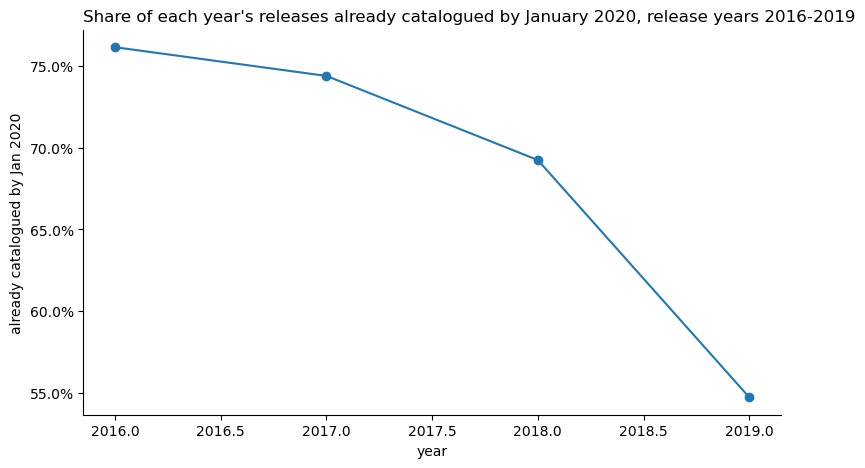

In [32]:
# Cataloguing lag: of each release year's releases in October 2026, how many were already in the January 2020 snapshot?
LAG_LAST_YEAR = int(config.BASE_SNAPSHOT) - 1   # 2020 in the January 2020 snapshot is a stub of a few days
lag = snapshots.cataloguing_lag(base["releases"], main["releases"]).cache()
lag_pd = lag.toPandas().sort_values("year")
lag_by_age = lag_pd[lag_pd.year <= LAG_LAST_YEAR].assign(age=lambda d: int(config.BASE_SNAPSHOT) - d.year)

ax = viz.plot_lines(lag_by_age, "year", "completeness",
                    title="Share of each year's releases already catalogued by January 2020, release years 2016-2019",
                    ylabel="already catalogued by Jan 2020", percent=True)
viz.save_figure(ax.figure, "cmp_cataloguing_lag")
export.export_table(lag_by_age, "cmp_lag")
lag_by_age.sort_values("age")[["age", "year", "n_new", "n_already", "n_added_later", "completeness"]]

,year,n_releases,age,completeness,partial_year,n_estimated,n_estimated_no_seasonal,seasonal_factor
0,2016,385281,11,NaN,False,385281.000000,385281.000000,1.00000
1,2017,390355,10,NaN,False,390355.000000,390355.000000,1.00000
2,2018,396710,9,NaN,False,396710.000000,396710.000000,1.00000
3,2019,394016,8,NaN,False,394016.000000,394016.000000,1.00000
4,2020,415671,7,NaN,False,415671.000000,415671.000000,1.00000
5,2021,391297,6,NaN,False,391297.000000,391297.000000,1.00000
6,2022,360863,5,NaN,False,360863.000000,360863.000000,1.00000
7,2023,347065,4,0.761678,False,455658.523359,455658.523359,1.00000
8,2024,312179,3,0.744079,False,419550.820420,419550.820420,1.00000
9,2025,280882,2,0.692513,False,405597.914366,405597.914366,1.00000


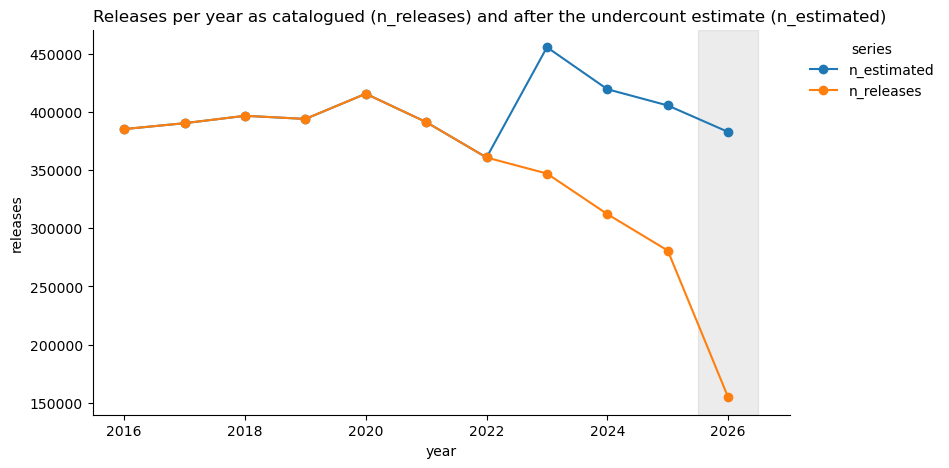

In [33]:
# Estimated number of releases per year after the undercount, with and without the 2026 seasonal factor.
yearly = main["releases"].groupBy("year").agg(F.count("*").alias("n_releases"))
undercount = snapshots.estimate_undercount(lag, yearly).toPandas()                          # config.PARTIAL_YEAR_SHARE: 2026 -> 0.739
undercount_flat = snapshots.estimate_undercount(lag, yearly, partial_year_share={}).toPandas()
cmp_undercount = undercount[["year", "n_releases", "age", "completeness", "partial_year", "n_estimated"]].merge(
    undercount_flat[["year", "n_estimated"]].rename(columns={"n_estimated": "n_estimated_no_seasonal"}), on="year"
).sort_values("year")
cmp_undercount["seasonal_factor"] = cmp_undercount.n_estimated / cmp_undercount.n_estimated_no_seasonal

long = cmp_undercount.melt(id_vars="year", value_vars=["n_releases", "n_estimated"], var_name="series", value_name="n")
ax = viz.plot_lines(long, "year", "n", series="series", ylabel="releases",
                    title="Releases per year as catalogued (n_releases) and after the undercount estimate (n_estimated)")
mark_partial(ax)
viz.save_figure(ax.figure, "cmp_undercount")
export.export_table(cmp_undercount, "cmp_undercount")
cmp_undercount

,format_name,CD,Cassette,File,Vinyl
age,year,,,,
1,2019,0.498,0.647,0.454,0.775
2,2018,0.629,0.813,0.629,0.869
3,2017,0.691,0.858,0.691,0.898
4,2016,0.690,0.882,0.728,0.910


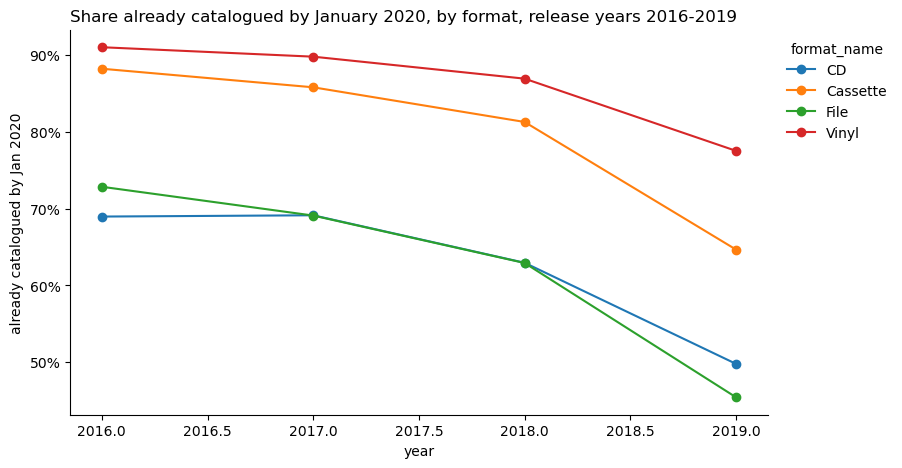

In [34]:
# Does the lag differ by format? Each release is grouped by its 2026 formats; release years up to LAG_LAST_YEAR only.
early = main["releases"].where(F.col("year") <= LAG_LAST_YEAR).select("release_id", "year").cache()
LAG_FORMATS = ("Vinyl", "CD", "Cassette", "File")
lag_fmt = (
    snapshots.cataloguing_lag_by(base["releases"], early, main["release_formats"].where(F.col("format_name").isin(*LAG_FORMATS)), "format_name")
    .toPandas().sort_values(["format_name", "year"]).assign(age=lambda d: int(config.BASE_SNAPSHOT) - d.year)
)
ax = viz.plot_lines(lag_fmt, "year", "completeness", series="format_name", percent=True,
                    title="Share already catalogued by January 2020, by format, release years 2016-2019",
                    ylabel="already catalogued by Jan 2020")
viz.save_figure(ax.figure, "cmp_lag_by_format")
export.export_table(lag_fmt, "cmp_lag_by_format")
lag_fmt.pivot(index=["age", "year"], columns="format_name", values="completeness").round(3)

,genre,Classical,Electronic,"Folk, World, & Country",Funk / Soul,Hip Hop,Jazz,Pop,Rock
age,year,,,,,,,,
1,2019,0.357,0.578,0.441,0.585,0.464,0.522,0.471,0.589
2,2018,0.535,0.737,0.571,0.702,0.632,0.647,0.613,0.717
3,2017,0.677,0.784,0.629,0.750,0.705,0.712,0.679,0.761
4,2016,0.568,0.806,0.647,0.769,0.762,0.715,0.697,0.783


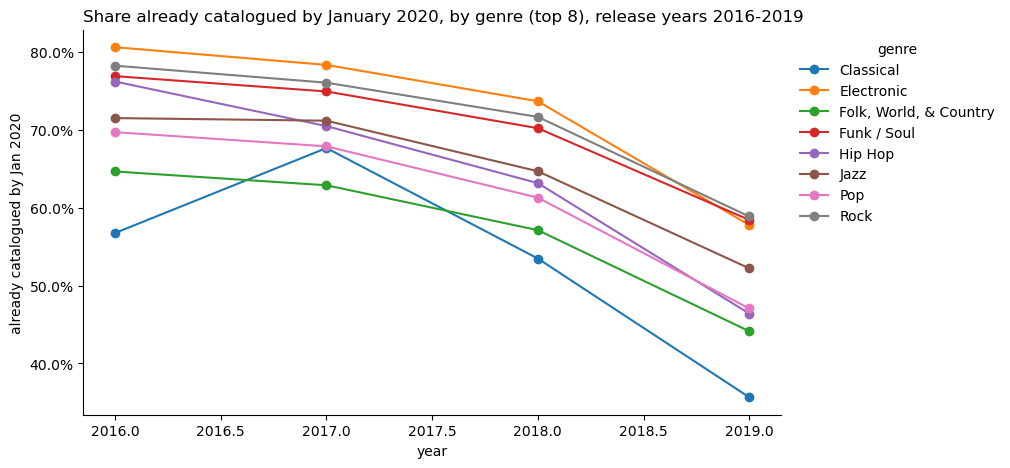

In [35]:
# The same for the 8 genres with the most releases in those years.
top_genres = [
    r.genre for r in (main["release_genres"].where(F.col("year") <= LAG_LAST_YEAR).groupBy("genre")
                      .agg(F.countDistinct("release_id").alias("n")).orderBy(F.desc("n")).limit(8).collect())
]
lag_gen = (
    snapshots.cataloguing_lag_by(base["releases"], early, main["release_genres"].where(F.col("genre").isin(top_genres)), "genre")
    .toPandas().sort_values(["genre", "year"]).assign(age=lambda d: int(config.BASE_SNAPSHOT) - d.year)
)
ax = viz.plot_lines(lag_gen, "year", "completeness", series="genre", percent=True,
                    title="Share already catalogued by January 2020, by genre (top 8), release years 2016-2019",
                    ylabel="already catalogued by Jan 2020")
viz.save_figure(ax.figure, "cmp_lag_by_genre")
export.export_table(lag_gen, "cmp_lag_by_genre")
lag_gen.pivot(index=["age", "year"], columns="genre", values="completeness").round(3)

> **Finding.** Of the 1,566,362 releases dated 2016-2019 in the October 2026 snapshot, 492,141 (31.4%) were added after January 2020. The share already catalogued in January 2020 grows with age: 54.7% of the 2019 releases, 69.3% of 2018, 74.4% of 2017 and 76.2% of 2016. Applying these rates to the October 2026 snapshot gives an estimated 405,598 releases for 2025 against 280,882 catalogued, 419,551 for 2024 (312,179) and 455,659 for 2023 (347,065), and for 2026 an estimated 382,830 for the full year against 154,790 catalogued in January-September (282,911 without the seasonal factor of 0.739). On this estimate the fall in catalogued releases after 2020 is mostly lag, not a fall in output. The lag also differs by group: by the end of their release year 77.5% of vinyl releases had been catalogued against 45.4% of File and 49.8% of CD releases, and 58.9% of Rock against 35.7% of Classical, so recent-year shares lean towards vinyl, Rock and Electronic.

### 5.5 RQ4 - Communities

*What communities of artists, producers, and labels emerge from the data, and do they match genre tags?*

Exploration and parameter choices: [`explorers/06_networks_and_communities.ipynb`](explorers/06_networks_and_communities.ipynb). Functions: `vinyl.networks`.

In [36]:
# Three graphs. Minimum edge weights come from config.GRAPH_MIN_WEIGHT; self-released labels (a DataFrame, see 5.3)
# are left out of the artist-label graph, otherwise "Not On Label" becomes one giant hub.
w = config.GRAPH_MIN_WEIGHT
with clustering.timed("edge lists"):
    collab_edges = networks.collaboration_edges(main["release_artists"], min_weight=w["collaboration"], max_artists_per_release=20).cache()
    credit_edges = networks.credit_edges(main["release_artists"], main["release_credits"], roles=config.PRODUCTION_ROLES, min_weight=w["credit"]).cache()
    artist_label_edges = networks.artist_label_edges(
        main["release_artists"], main["release_labels"], min_weight=w["artist_label"], exclude_label_ids=self_released
    ).cache()
    edge_counts = {"collaboration": collab_edges.count(), "credit": credit_edges.count(), "artist-label": artist_label_edges.count()}
pd.DataFrame({"graph": k, "min_weight": w[k.replace("-", "_")], "edges": n} for k, n in edge_counts.items())

[edge lists] 269.6 s


,graph,min_weight,edges
0,collaboration,2,151838
1,credit,3,334197
2,artist-label,3,336173


In [37]:
# Collect the edge lists on the driver and build the graphs. The artist-label graph uses prefixed ids (a123 / l123).
with clustering.timed("graphs"):
    edge_tables = {
        "collaboration": collab_edges.toPandas(),
        "credit": credit_edges.toPandas(),
        "artist-label": networks.prefixed_bipartite(artist_label_edges).toPandas(),
    }
    graphs = {k: networks.to_igraph(v) for k, v in edge_tables.items()}
pd.DataFrame({"graph": k, "nodes": g.vcount(), "edges": g.ecount()} for k, g in graphs.items())

[graphs] 67.4 s


,graph,nodes,edges
0,collaboration,113631,151838
1,credit,209487,334197
2,artist-label,289002,336173


In [38]:
# Names only for the nodes that are in the graphs, then PageRank (betweenness stays off: too slow on these graphs).
with clustering.timed("names and centrality"):
    names = {
        "collaboration": networks.node_names(main["artists"], ids=graphs["collaboration"].vs["name"]),
        "credit": networks.node_names(main["artists"], ids=graphs["credit"].vs["name"]),
        "artist-label": networks.node_names(main["artists"], main["labels"], prefixed=True, ids=graphs["artist-label"].vs["name"]),
    }
    centrality = {k: networks.centrality_table(g, betweenness=False) for k, g in graphs.items()}

top_pagerank = pd.concat(
    [
        centrality[k].nlargest(15, "pagerank").merge(names[k], on="node", how="left")
        .assign(graph=k, rank=lambda d: np.arange(1, len(d) + 1), node=lambda d: d["node"].astype(str))
        for k in graphs
    ],
    ignore_index=True,
)[["graph", "rank", "node", "name", "degree", "strength", "pagerank"]]
export.export_table(top_pagerank, "rq4_top_pagerank")
top_pagerank

[names and centrality] 203.1 s


,graph,rank,node,name,degree,strength,pagerank
0,collaboration,1,95537,Johann Sebastian Bach,823,3982.0,0.001220
1,collaboration,2,95544,Ludwig van Beethoven,831,4663.0,0.001170
2,collaboration,3,95546,Wolfgang Amadeus Mozart,850,3720.0,0.000990
3,collaboration,4,304975,Johannes Brahms,544,2624.0,0.000669
4,collaboration,5,283469,Franz Schubert,381,1641.0,0.000448
5,collaboration,6,578727,Robert Schumann,337,1645.0,0.000426
6,collaboration,7,999914,Pyotr Ilyich Tchaikovsky,300,1639.0,0.000375
7,collaboration,8,260744,Berliner Philharmoniker,199,1855.0,0.000366
8,collaboration,9,96123,Claude Debussy,282,1462.0,0.000366
9,collaboration,10,216140,Maurice Ravel,282,1467.0,0.000357


In [39]:
LEIDEN_RESOLUTION, LEIDEN_SEED = 1.0, 42
with clustering.timed("Leiden"):
    communities = {k: networks.leiden_communities(g, resolution=LEIDEN_RESOLUTION, seed=LEIDEN_SEED) for k, g in graphs.items()}
for k, c in communities.items():
    sizes = c["community"].value_counts()
    print(f"{k:14s} communities {len(sizes):>8,}  >=50 nodes {(sizes >= 50).sum():>5,}  largest {sizes.iloc[0]:>8,}  modularity {c.attrs['modularity']:.4f}")

[Leiden] 291.5 s


collaboration  communities   23,939  >=50 nodes    84  largest    4,870  modularity 0.9282
credit         communities   17,057  >=50 nodes    78  largest   10,436  modularity 0.8251
artist-label   communities   38,390  >=50 nodes   130  largest    8,914  modularity 0.9183


In [40]:
# Agreement between the communities and each artist's dominant genre and style. Dominant tags are collected only for
# artists that are in a graph. The credit graph also holds people who are never a main artist: they have no tag.
artist_ids_in_graphs = sorted(
    set(networks.graph_artist_ids(graphs["collaboration"]))
    | set(networks.graph_artist_ids(graphs["credit"]))
    | set(networks.graph_artist_ids(graphs["artist-label"], prefixed=True))
)
in_graphs = spark.createDataFrame([(i,) for i in artist_ids_in_graphs], "artist_id long")
graph_artists = main["release_artists"].join(in_graphs, "artist_id")
dominant = {
    "genre": networks.artist_dominant_tag(graph_artists, main["release_genres"], "genre").toPandas().rename(columns={"artist_id": "node"}),
    "style": networks.artist_dominant_tag(graph_artists, main["release_styles"], "style").toPandas().rename(columns={"artist_id": "node"}),
}
# Artist-label nodes are prefixed, so prefix the tag table too (label nodes then have no tag).
node_tags = {
    (k, tag): (t.assign(node="a" + t["node"].astype(str)) if k == "artist-label" else t)
    for k in graphs for tag, t in dominant.items()
}

rows = []
for k, g in graphs.items():
    n_artist_nodes = len(networks.graph_artist_ids(g, prefixed=(k == "artist-label")))
    for tag in ("genre", "style"):
        rows.append({"graph": k, "tag": tag, "n_artist_nodes": n_artist_nodes,
                     **networks.community_tag_agreement(communities[k], node_tags[(k, tag)], tag_col=tag)})
agreement = pd.DataFrame(rows)
agreement["share_tagged"] = agreement["n_nodes"] / agreement["n_artist_nodes"]

graph_stats = pd.DataFrame({
    "graph": list(graphs),
    "min_weight": [w[k.replace("-", "_")] for k in graphs],
    "nodes": [g.vcount() for g in graphs.values()],
    "edges": [g.ecount() for g in graphs.values()],
    "communities": [communities[k]["community"].nunique() for k in graphs],
    "communities_ge50": [int((communities[k]["community"].value_counts() >= 50).sum()) for k in graphs],
    "largest_community_share": [communities[k]["community"].value_counts(normalize=True).iloc[0] for k in graphs],
    "modularity": [communities[k].attrs["modularity"] for k in graphs],
})
graph_summary = graph_stats.merge(agreement, on="graph")
export.export_table(graph_summary, "rq4_graph_summary")
graph_summary[["graph", "min_weight", "nodes", "edges", "communities", "communities_ge50", "modularity",
               "tag", "n_nodes", "share_tagged", "nmi", "ari", "purity"]].round(4)

,graph,min_weight,nodes,edges,communities,communities_ge50,modularity,tag,n_nodes,share_tagged,nmi,ari,purity
0,collaboration,2,113631,151838,23939,84,0.9282,genre,113631,1.0000,0.3045,0.0300,0.8707
1,collaboration,2,113631,151838,23939,84,0.9282,style,109557,0.9641,0.5643,0.1445,0.6046
2,credit,3,209487,334197,17057,78,0.8251,genre,108848,0.5196,0.2327,0.0398,0.6678
3,credit,3,209487,334197,17057,78,0.8251,style,104470,0.4987,0.3814,0.0567,0.3158
4,artist-label,3,289002,336173,38390,130,0.9183,genre,203212,1.0000,0.2774,0.0372,0.8089
5,artist-label,3,289002,336173,38390,130,0.9183,style,197029,0.9696,0.4866,0.1413,0.4409


In [41]:
# The 10 largest communities of the collaboration and artist-label graphs: key nodes, most common genres and styles.
def top_communities(graph_name: str) -> pd.DataFrame:
    """Describe the 10 largest communities of one graph with genre and style tags side by side."""
    parts = {
        tag: networks.describe_communities(communities[graph_name], centrality[graph_name], names[graph_name],
                                           node_tags=node_tags[(graph_name, tag)], top_n=5, min_size=50, tag_col=tag).head(10)
        for tag in ("genre", "style")
    }
    genre = parts["genre"].rename(columns={"n_tagged": "n_genre_tagged", "top_tags": "top_genres", "tag_purity": "genre_purity"})
    style = parts["style"].rename(columns={"n_tagged": "n_style_tagged", "top_tags": "top_styles", "tag_purity": "style_purity"})
    return genre.merge(style[["community", "n_style_tagged", "top_styles", "style_purity"]], on="community", how="left")


communities_collab = top_communities("collaboration")
communities_artist_label = top_communities("artist-label")
export.export_table(communities_collab, "rq4_communities_collab")
export.export_table(communities_artist_label, "rq4_communities_artist_label")
pd.set_option("display.max_colwidth", 120)
communities_collab

,community,size,top_nodes,n_genre_tagged,top_genres,genre_purity,n_style_tagged,top_styles,style_purity
0,8,4870,"Ludwig van Beethoven, Wolfgang Amadeus Mozart, Johannes Brahms, Franz Schubert, Robert Schumann",4870,"Classical (0.96), Stage & Screen (0.02), Jazz (0.01)",0.959754,4844,"Romantic (0.28), Modern (0.21), Classical (0.12)",0.277250
1,13,3627,"Armin van Buuren, Alok (4), Steve Aoki, Dimitri Vegas & Like Mike, Hardwell",3627,"Electronic (0.88), Pop (0.07), Hip Hop (0.01)",0.881720,3601,"House (0.27), Electro House (0.19), Progressive House (0.10)",0.269092
2,1,3433,"Dj T.H., Talla 2XLC, RAM (38), Christina Novelli, Rene Ablaze",3433,"Electronic (0.99), Pop (0.01), Stage & Screen (0.00)",0.987475,3430,"Trance (0.62), Progressive Trance (0.12), Progressive House (0.07)",0.619242
3,7,3227,"Ernesto Rodrigues, Guilherme Rodrigues, Bill Laswell, Merzbow, John Edwards",3227,"Jazz (0.60), Electronic (0.23), Classical (0.07)",0.599628,3195,"Free Improvisation (0.36), Experimental (0.18), Avant-garde Jazz (0.08)",0.357433
4,4,2991,"David Guetta, Ty Dolla $ign, Diplo, French Montana, Snoop Dogg",2991,"Hip Hop (0.40), Electronic (0.24), Pop (0.16)",0.403210,2745,"Trap (0.18), House (0.09), Contemporary R&B (0.08)",0.181421
5,14,2768,"Agathocles, Radek Kopel, Vitimas Do Crack, Theonugraha, Crepuscular Entity",2768,"Electronic (0.50), Rock (0.49), Non-Music (0.01)",0.496749,2767,"Noise (0.31), Goregrind (0.18), Grindcore (0.12)",0.306469
6,6,2516,"DJ Spen, Todd Terry, Green Velvet, Robert Owens, David Morales",2516,"Electronic (0.91), Funk / Soul (0.04), Pop (0.01)",0.911765,2510,"House (0.53), Tech House (0.10), Deep House (0.09)",0.533068
7,27,2037,"Johann Sebastian Bach, Antonio Vivaldi, Georg Friedrich Händel, Georg Philipp Telemann, Claudio Monteverdi",2037,"Classical (0.98), Jazz (0.01), Folk, World, & Country (0.00)",0.981836,2026,"Baroque (0.74), Classical (0.05), Choral (0.04)",0.742843
8,34,1779,"Alchemist, DJ Muggs, Conway The Machine, Machacha, Big Ghost LTD",1779,"Hip Hop (0.88), Electronic (0.06), Funk / Soul (0.03)",0.879146,1509,"Boom Bap (0.35), Hardcore Hip-Hop (0.14), Conscious (0.12)",0.353214
9,40,1756,"MC Alee, Dr. Peacock, Deadly Guns, Andy The Core, Paul Elstak",1756,"Electronic (0.98), Hip Hop (0.01), Pop (0.01)",0.984055,1755,"Hardcore (0.41), Hardstyle (0.39), Happy Hardcore (0.03)",0.414245


In [42]:
communities_artist_label

,community,size,top_nodes,n_genre_tagged,top_genres,genre_purity,n_style_tagged,top_styles,style_purity
0,33,8914,"Transcending Obscurity Records, Nuclear War Now! Productions, Iron Bonehead Productions, Hells Headbangers, Vendetta...",7373,"Rock (0.87), Electronic (0.12), Folk, World, & Country (0.01)",0.866676,7372,"Black Metal (0.48), Death Metal (0.19), Dungeon Synth (0.06)",0.478974
1,25,7190,"Armada (4), Artist Intelligence Agency, Monstercat, Revealed Recordings, Spinnin' Records",5907,"Electronic (0.96), Pop (0.02), Hip Hop (0.01)",0.959878,5872,"House (0.25), Electro House (0.15), Progressive House (0.12)",0.247956
2,18,6792,"Deutsche Grammophon, Naxos, Decca, Sony Classical, Warner Classics",6207,"Classical (0.93), Jazz (0.02), Pop (0.01)",0.932657,6163,"Romantic (0.19), Baroque (0.19), Contemporary (0.16)",0.190654
3,7,6773,"Universal Music Group, Universal Music, Polydor, Island Records, Interscope Records",4303,"Pop (0.33), Rock (0.21), Hip Hop (0.17)",0.334650,4065,"Pop Rock (0.06), Trap (0.05), Indie Pop (0.05)",0.062977
4,2,6585,"High Roller Records, Nuclear Blast, Napalm Records, Metal Blade Records, Century Media",5301,"Rock (0.95), Electronic (0.02), Folk, World, & Country (0.01)",0.948123,5280,"Heavy Metal (0.21), Black Metal (0.12), Death Metal (0.10)",0.206061
5,3,6341,"Zegema Beach Records, No Time Records, Vægtløs, Agathocles, Grindfather Productions",4353,"Rock (0.91), Electronic (0.04), Hip Hop (0.01)",0.908109,4316,"Punk (0.16), Hardcore (0.15), Grindcore (0.10)",0.162651
6,20,5517,"Sony Music, Columbia, RCA, Epic, Music On Vinyl",3734,"Pop (0.31), Rock (0.23), Hip Hop (0.13)",0.306106,3525,"Pop Rock (0.06), Alternative Rock (0.05), Ballad (0.04)",0.061560
7,14,5032,"Empire, BarsOverBs, Copenhagen Crates, Chopped Herring Records, Vinyl Digital",3477,"Hip Hop (0.88), Electronic (0.05), Funk / Soul (0.03)",0.880069,2966,"Boom Bap (0.29), Instrumental (0.14), Conscious (0.12)",0.293999
8,8,4968,"Nervous Records, YHV Records, Quantize Recordings, BBE, Vamos Music",4087,"Electronic (0.93), Funk / Soul (0.04), Jazz (0.01)",0.934426,4079,"House (0.49), Tech House (0.13), Deep House (0.12)",0.489826
9,9,4382,"Solid Records (6), Blue Note, ECM Records, Verve Records, Real Gone Music",3472,"Jazz (0.58), Funk / Soul (0.10), Rock (0.09)",0.578053,3372,"Contemporary Jazz (0.20), Bop (0.05), Post Bop (0.04)",0.200771


In [43]:
# How stable are the collaboration communities when the Leiden resolution changes? (The credit graph sweep takes about 7 min and is skipped here.)
with clustering.timed("collaboration resolution sweep"):
    resolution_sweep = networks.resolution_sweep(
        graphs["collaboration"], resolutions=(0.5, 1.0, 2.0), seed=LEIDEN_SEED, reference=LEIDEN_RESOLUTION
    ).assign(graph="collaboration")
export.export_table(resolution_sweep, "rq4_resolution_sweep")
resolution_sweep

[collaboration resolution sweep] 107.8 s


,resolution,n_communities,n_communities_ge50,largest_share,modularity,nmi_vs_reference,graph
0,0.5,23864,57,0.068080,0.920419,0.966256,collaboration
1,1.0,23939,84,0.042858,0.928191,1.000000,collaboration
2,2.0,24036,118,0.028091,0.921134,0.963483,collaboration


> **Finding.** Leiden (Traag et al. 2019) finds 23,939 communities in the collaboration graph, 17,057 in the credit graph and 38,390 in the artist-label graph, with modularity 0.93, 0.83 and 0.92; most are tiny, and only 84, 78 and 130 have at least 50 nodes. The largest collaboration communities are recognisable scenes: Romantic-era classical (4,870 artists, 96% Classical), festival EDM around Armin van Buuren and Steve Aoki (3,627), trance (3,433), free improvisation (3,227), a pop and hip-hop crossover around David Guetta and Snoop Dogg (2,991), noise and grindcore (2,768), house (2,516), Baroque (2,037), boom bap (1,779) and hardcore and hardstyle (1,756). Communities follow styles better than genres once chance agreement is accounted for: in the collaboration graph genre purity is high (0.87) but NMI is only 0.30 and ARI 0.03, because most communities are simply Electronic or Rock, while style gives NMI 0.56 and ARI 0.14; the artist-label graph is similar (style NMI 0.49) and the credit graph weaker (0.38, with only half its nodes tagged). The artist-label graph also shows ownership: Universal's labels (Universal Music Group, Polydor, Island, Interscope) and Sony's (Sony Music, Columbia, RCA, Epic) each form one community of mixed genres (top-genre share 0.33 and 0.31), whereas classical labels of different owners, among them Deutsche Grammophon, Naxos, Sony Classical and Warner Classics, share one community that is 93% Classical. The collaboration communities hardly change with the resolution parameter (NMI 0.97 at 0.5 and 0.96 at 2.0 against the run at 1.0).

### 5.6 Artist clustering

*Do artists group into recognisable types when described by what they release and who they work with?*

Exploration and parameter choices: [`explorers/07_artist_clustering.ipynb`](explorers/07_artist_clustering.ipynb). Functions: `vinyl.clustering`.

Artists with at least 5 releases in 2016-2026 are described by three blocks of features. The profile block (`clustering.artist_profile`) holds the number of releases and labels, the career span inside the window and the share of vinyl, CD, cassette and file releases. The style block (`clustering.style_tfidf`) holds TF-IDF weights of each artist's styles, for styles used by at least 20 of the kept artists. The graph block (`clustering.node2vec_embeddings`) holds 64-dimensional node2vec embeddings (Grover and Leskovec 2016) from the collaboration graph of the same artists; artists outside that graph get a zero vector and a flag. `clustering.combine_features` standardises the profile block, reduces the TF-IDF block with a truncated SVD, scales the three blocks so that each contributes equally and joins them. UMAP (McInnes et al. 2018; 30 neighbours, cosine distance) reduces the result to 10 dimensions for clustering and 2 for the plot, and HDBSCAN (Campello et al. 2013; McInnes et al. 2017) groups the 10-dimensional points with a minimum cluster size of 100, chosen from the sweep in explorer 07, and marks the rest as noise.

node2vec and UMAP are the slow steps: when the cache was built, the two UMAP runs and their shared neighbour graph took about 2 h 48 min. Their outputs are saved under `$DISCOGS_DATA_DIR/derived/2026/` and reused when they match the current artist set, so this section reruns in minutes.

In [44]:
# Artist features (Spark): profile of artists with at least 5 releases, and style TF-IDF for those artists.
real_artists = main["release_artists"].where(~F.col("artist_id").isin(list(networks.PLACEHOLDER_ARTIST_IDS)))   # as in 5.3
with clustering.timed("artist_profile"):
    profile = clustering.artist_profile(real_artists, main["release_formats"], main["release_labels"], min_releases=5).cache()
    print(f"{profile.count():,} artists kept")
kept_artists = real_artists.join(profile.select("artist_id"), "artist_id", "left_semi")
tfidf = clustering.style_tfidf(kept_artists, main["release_styles"], min_artists=20)

194,105 artists kept
[artist_profile] 320.7 s


In [45]:
# node2vec on the collaboration graph of the kept artists. The slow steps are cached under $DISCOGS_DATA_DIR/derived/<snapshot>/
# (written by explorer 07 or by this cell) and reused when they match this run. REUSE_CACHE = False recomputes everything.
REUSE_CACHE = True
DERIVED = Path(config.DATA_DIR) / "derived" / config.MAIN_SNAPSHOT
assert not str(DERIVED).startswith("/mnt/data"), "derived files must not go under /mnt/data"
DERIVED.mkdir(parents=True, exist_ok=True)

kept_edges = networks.collaboration_edges(kept_artists, min_weight=config.GRAPH_MIN_WEIGHT["collaboration"]).toPandas()
graph_nodes = set(kept_edges["src"]) | set(kept_edges["dst"])
print(f"{len(kept_edges):,} edges, {len(graph_nodes):,} nodes")

n2v_file = DERIVED / "artist_n2v.parquet"
embeddings = None
if REUSE_CACHE and n2v_file.exists():
    embeddings = pd.read_parquet(n2v_file)
    if set(embeddings["node"]) != graph_nodes:
        print("saved embeddings do not match this graph; recomputing")
        embeddings = None
    else:
        print("loaded", n2v_file)
if embeddings is None:
    with clustering.timed("node2vec"):
        embeddings = clustering.node2vec_embeddings(kept_edges, dimensions=64, walk_length=30, num_walks=10, p=1.0, q=1.0)
    embeddings.to_parquet(n2v_file, engine="pyarrow", index=False)
    print("saved", n2v_file)
embeddings.shape

98,440 edges, 63,088 nodes


loaded /home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/data/derived/2026/artist_n2v.parquet


(63088, 65)

In [46]:
# Combine the features and reduce them with UMAP (2 components for the plot, 10 for clustering).
profile_pd = profile.toPandas()
tfidf_pd = tfidf.toPandas()

files = {name: DERIVED / f"{name}.npy" for name in ("features", "artist_ids", "embedding_2d", "embedding_10d")}
umap_file = DERIVED / "umap_params.json"
# Files written by explorer 07 have no params file; it used the reduce_umap default of 30 neighbours.
saved_neighbors = json.loads(umap_file.read_text())["n_neighbors"] if umap_file.exists() else 30

cached = REUSE_CACHE and all(f.exists() for f in files.values())
if cached:
    artist_ids = pd.Series(np.load(files["artist_ids"]), name="artist_id")
    cached = set(artist_ids) == set(profile_pd["artist_id"])
    if not cached:
        print("saved features do not match the artist profile; recomputing")
    elif saved_neighbors != config.UMAP_N_NEIGHBORS:
        print(f"saved UMAP used n_neighbors={saved_neighbors}, config says {config.UMAP_N_NEIGHBORS}; recomputing")
        cached = False
if cached:
    features, embedding_2d, embedding_10d = (np.load(files[k]) for k in ("features", "embedding_2d", "embedding_10d"))
    print("loaded features and UMAP embeddings from", DERIVED)
else:
    with clustering.timed("combine_features"):
        features, artist_ids = clustering.combine_features(profile_pd, tfidf_pd, embeddings)
    # One neighbour graph for both runs. UMAP runs unseeded so it can use every core;
    # the saved files are what makes the report reproducible.
    with clustering.timed("UMAP neighbours"):
        knn = clustering.umap_knn(features, n_neighbors=config.UMAP_N_NEIGHBORS)
    with clustering.timed("UMAP 2d"):
        embedding_2d = clustering.reduce_umap(features, n_components=2, n_neighbors=config.UMAP_N_NEIGHBORS, knn=knn)
    with clustering.timed("UMAP 10d"):
        embedding_10d = clustering.reduce_umap(features, n_components=10, n_neighbors=config.UMAP_N_NEIGHBORS, knn=knn)
    for name, array in (("features", features), ("artist_ids", np.asarray(artist_ids)),
                        ("embedding_2d", embedding_2d), ("embedding_10d", embedding_10d)):
        np.save(files[name], array)
    umap_file.write_text(json.dumps({"n_neighbors": config.UMAP_N_NEIGHBORS}))
    print("saved", ", ".join(f.name for f in files.values()), "to", DERIVED)
features.shape, embedding_10d.shape

loaded features and UMAP embeddings from /home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/data/derived/2026


((194105, 122), (194105, 10))

In [47]:
# HDBSCAN on the 10-dimensional embedding.
with clustering.timed("HDBSCAN"):
    cluster_labels = clustering.cluster_hdbscan(embedding_10d, min_cluster_size=config.HDBSCAN_MIN_CLUSTER_SIZE)
n_clusters = len(set(cluster_labels) - {-1})
noise_share = float((cluster_labels == -1).mean())
print(f"{n_clusters} clusters; {noise_share:.1%} of {len(cluster_labels):,} artists are noise")

[HDBSCAN] 135.7 s


149 clusters; 13.2% of 194,105 artists are noise


/home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/figures/rq4_clusters.png


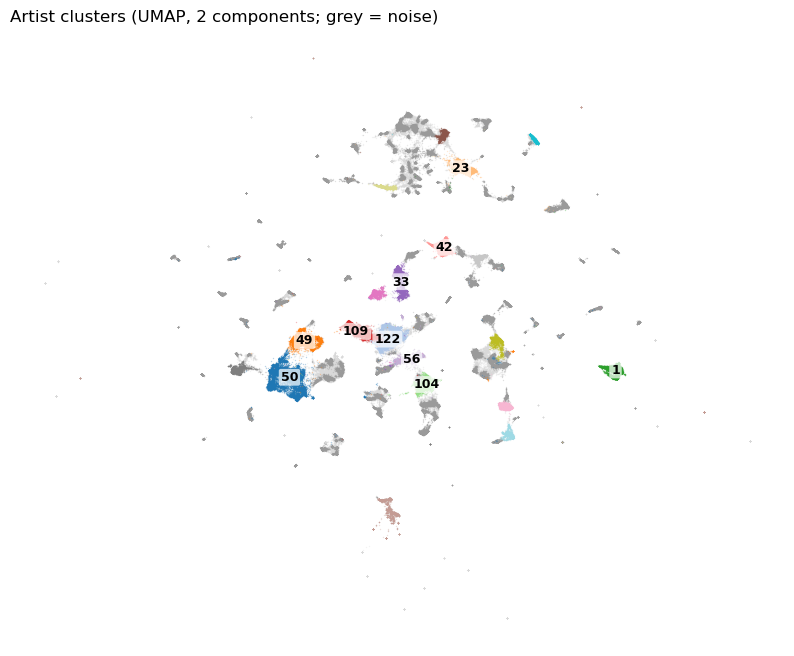

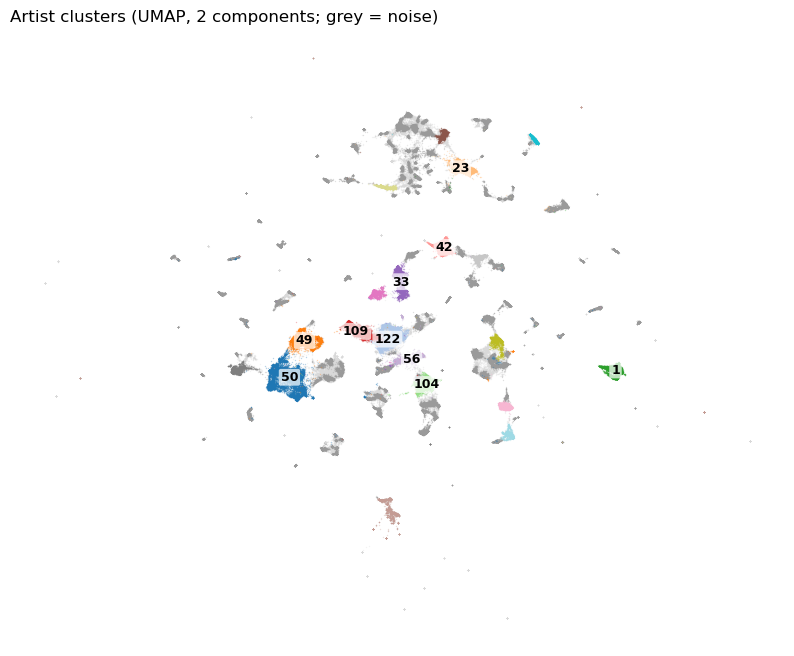

In [48]:
fig = clustering.plot_clusters_2d(embedding_2d, cluster_labels, title="Artist clusters (UMAP, 2 components; grey = noise)")
print(viz.save_figure(fig, "rq4_clusters"))
fig

In [49]:
# One row per cluster: size, top styles, format mix, career span and example artists (noise is its own row).
summary = clustering.describe_clusters(cluster_labels, artist_ids, profile_pd, tfidf_pd)
cluster_table = summary.assign(
    top_styles=summary["top_styles"].map(lambda pairs: "; ".join(f"{style} ({value:.3f})" for style, value in pairs)),
    examples=summary["examples"].map(lambda names: "; ".join(map(str, names))),
)
export.export_table(cluster_table, "rq4_clusters")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
cluster_table.head(30)

,cluster,size,share,is_noise,top_styles,mean_share_vinyl,mean_share_cd,mean_share_cassette,mean_share_file,median_career_span,median_n_releases,median_first_year,examples
0,-1,25640,0.132093,True,Techno (0.198); House (0.155); Tech House (0.103),0.206534,0.103292,0.048443,0.599438,6.0,9.0,2017.0,David Bowie; Elvis Presley; King Gizzard And The Lizard Wizard; Kiss; The Beatles
1,50,13063,0.067299,False,Experimental (0.312); Ambient (0.294); Noise (0.254),0.107629,0.082595,0.172402,0.557767,5.0,8.0,2017.0,This Is What I Hear When You Talk; Naoki Kasugai; D*Time; TCLB; Buckethead
2,122,8506,0.043822,False,Indie Rock (0.678); Alternative Rock (0.615); Shoegaze (0.136),0.373235,0.191138,0.062417,0.312291,6.0,8.0,2017.0,The Cure; The Sisters Of Mercy; Radiohead; Marilyn Manson; Twenty One Pilots
3,49,6255,0.032225,False,Synth-pop (0.464); Synthwave (0.305); Electro (0.221),0.191052,0.128321,0.057688,0.577211,6.0,9.0,2017.0,John Crozier Harrison; Kraftwerk; Closed Mouth; Boy Harsher; Fear Incorporated
4,23,6017,0.030999,False,Noise (0.317); Experimental (0.301); Ambient (0.276),0.141546,0.096839,0.176693,0.487510,7.0,15.0,2017.0,Nosferatu 1922; Merzlux; Tole Ache; Eugene Chadbourne; Lord Cernunnos
5,1,5379,0.027712,False,Romantic (0.530); Modern (0.435); Contemporary (0.412),0.056821,0.736937,0.001140,0.123232,9.0,9.0,2016.0,Johann Sebastian Bach; Ludwig van Beethoven; Wolfgang Amadeus Mozart; Johannes Brahms; Franz Schubert
6,104,4827,0.024868,False,Punk (1.369); Pop Punk (0.235); Garage Rock (0.167),0.500622,0.168278,0.116943,0.163203,6.0,7.0,2017.0,Sex Pistols; Misfits; Green Day; Ramones; The Offspring
7,109,4662,0.024018,False,Indie Pop (1.216); Indie Rock (0.275); Alt-Pop (0.157),0.298228,0.166319,0.042383,0.430390,6.0,8.0,2017.0,"Fine.; The Reds, Pinks And Purples; Herr Wade; Kevin Robertson (5); Melanie Martinez (2)"
8,42,4299,0.022148,False,Black Metal (2.044); Atmospheric Black Metal (0.269); Depressive Black Metal (0.140),0.260099,0.252734,0.242641,0.183839,6.0,8.0,2018.0,Enslaved; Cradle Of Filth; Samael; Dark Funeral; Thy Catafalque
9,33,4268,0.021988,False,Heavy Metal (1.031); Hard Rock (0.918); Power Metal (0.327),0.334274,0.427384,0.038256,0.153852,7.0,8.0,2017.0,Led Zeppelin; Mötley Crüe; Rainbow; W.A.S.P.; Sabaton


In [50]:
# Compare the clusters with (a) Leiden communities on the same collaboration edges and (b) each artist's dominant genre.
with clustering.timed("Leiden on the clustered artists"):
    kept_communities = networks.leiden_communities(networks.to_igraph(kept_edges), resolution=LEIDEN_RESOLUTION, seed=LEIDEN_SEED)
vs_leiden = clustering.compare_partitions(
    cluster_labels, kept_communities["community"].to_numpy(), artist_ids, kept_communities["node"]
)
dominant_genre = networks.artist_dominant_tag(kept_artists, main["release_genres"], "genre").select("artist_id", "genre").toPandas()
vs_genre = clustering.compare_partitions(
    cluster_labels, dominant_genre["genre"].to_numpy(), artist_ids, dominant_genre["artist_id"]
)
cluster_agreement = pd.DataFrame(
    [
        {"compared_with": "Leiden communities (collaboration graph)", **{k: v for k, v in vs_leiden.items() if k != "contingency"}},
        {"compared_with": "dominant genre", **{k: v for k, v in vs_genre.items() if k != "contingency"}},
    ]
).assign(n_clusters=n_clusters, noise_share=noise_share)
export.export_table(cluster_agreement, "rq4_cluster_agreement")
display(cluster_agreement)
display(vs_leiden["contingency"])   # 10 largest clusters (rows) by 10 largest Leiden communities (columns)
vs_genre["contingency"]             # 10 largest clusters (rows) by 10 largest genres (columns)

[Leiden on the clustered artists] 21.8 s


,compared_with,n_common,n_compared,nmi,ari,n_clusters,noise_share
0,Leiden communities (collaboration graph),63088,53362,0.562144,0.296657,149,0.132093
1,dominant genre,194105,168465,0.400490,0.077382,149,0.132093


b,4,14,0,10,9,2,28,5,25,18
a,,,,,,,,,,
23,7,481,5,1028,3,22,3,4,19,17
1,2985,90,0,0,1,5,0,1206,0,2
127,1,14,45,16,20,8,21,0,2,18
103,1,5,0,49,5,5,0,0,8,4
54,0,0,1838,0,51,4,6,0,1,0
41,2,1369,0,11,0,0,0,0,2,3
40,16,150,0,1,0,9,0,3,5,4
135,0,0,40,0,1273,282,9,0,1,0
85,0,0,0,0,3,10,2,0,675,3


b,Electronic,Rock,Pop,Hip Hop,Classical,"Folk, World, & Country",Jazz,Funk / Soul,Reggae,Stage & Screen
a,,,,,,,,,,
50,11406,935,77,96,92,102,105,6,0,9
122,397,7470,294,49,4,185,26,16,0,4
49,4770,909,453,56,6,17,7,13,3,0
23,5410,301,12,29,51,65,43,0,0,6
1,22,10,7,0,5267,26,20,0,0,5
104,80,4613,21,13,0,60,3,4,17,1
109,510,959,2820,27,5,238,25,34,2,0
42,85,4200,0,1,5,6,1,0,0,0
33,40,4173,18,5,3,8,4,4,0,1


In [51]:
# A 2-D sample for the dashboard: at most 20,000 artists, seed 42.
n_points = min(20_000, len(artist_ids))
pick = np.sort(np.random.default_rng(42).choice(len(artist_ids), size=n_points, replace=False))
artist_names = profile_pd.set_index("artist_id")["artist_name"]
cluster_points = pd.DataFrame({
    "x": embedding_2d[pick, 0],
    "y": embedding_2d[pick, 1],
    "cluster": cluster_labels[pick],
    "artist_name": artist_names.reindex(np.asarray(artist_ids)[pick]).to_numpy(),
})
export.export_table(cluster_points, "rq4_cluster_points")
cluster_points.head()

,x,y,cluster,artist_name
0,11.281233,17.049353,128,The Persuader
1,3.997795,-0.025249,50,Wagon Christ
2,5.617639,0.208158,-1,David Alvarado
3,10.874017,17.845375,132,Green Velvet
4,14.118123,-0.307119,142,Fresh & Low


> **Finding.** HDBSCAN finds 149 clusters among the 194,105 artists and leaves 25,640 (13.2%) as noise. Most clusters are defined by one or two styles together with a format profile: the largest is experimental, ambient and noise (13,063 artists, 6.7%), followed by indie and alternative rock (8,506), synth-pop and synthwave (6,255), a second noise cluster of very prolific artists (6,017, median 15 releases) and Romantic and modern classical (5,379, on average 74% of their releases on CD). Several styles split into a digital and a physical cluster, for example techno (cluster 146, on average 97% of releases as files, against cluster 147 at 29%) and dub (cluster 51 at 91% against cluster 3 at 15%), so the format mix separates release cultures within a style. The noise group includes the biggest catalogue acts, such as David Bowie, Elvis Presley and The Beatles, whose output spans too many styles and formats for any one cluster. The clusters agree moderately with the Leiden communities on the same collaboration edges (NMI 0.56, ARI 0.30 over 53,362 artists) and less with each artist's dominant genre (NMI 0.40, ARI 0.08), which fits clusters built on style and format rather than genre.

In [52]:
# Every table written for the dashboard, with a one-line description. Files go to export.DASHBOARD_DATA_DIR.
manifest = {
    "data_summary": "Releases in scope, linked artists and labels, share of releases with a style, and how the year filter was applied.",
    "rq1_genre_shares": "Share of each year's releases tagged with each genre.",
    "rq1_style_movers": "Style share in 2016 and in the last full year, with the change; all styles with at least 500 releases.",
    "rq1_entropy": "Style entropy and evenness by year, with entropy over 2016 styles only and the share of new styles.",
    "rq1_entropy_sensitivity": "Style evenness on all releases and on equal-size random samples (mean, min, max) by year.",
    "rq1_style_network": "Style co-occurrence network by year: nodes, edges, density, components, modularity.",
    "rq1_movers_no_prolific": "Top style movers with and without prolific artist-years, with the Spearman correlation of the two rankings.",
    "rq2_format_shares": "Share of each year's releases by format; minor formats grouped as Other.",
    "rq2_vinyl_reissues": "Vinyl releases per year: new, reissues and reissue share, for the three reissue definitions.",
    "rq2_growth_explained": "Share of the growth in vinyl releases explained by reissues, for the three definitions.",
    "rq2_reissue_by_genre": "Reissue share of vinyl releases by year and genre.",
    "rq2_reissue_age": "Age of the master on vinyl and CD releases by year and age bin, with the median age.",
    "rq2_pressing_plants": "Share of vinyl releases naming a pressing plant, and the top 15 plants by year.",
    "rq3_major_share": "Share of each year's releases on labels of Universal, Sony, Warner and independents.",
    "rq3_group_concentration": "Artist concentration (HHI, top artist share) of each label group, overall and by year.",
    "rq3_parent_coverage": "Releases by year and the parent information of their labels, with a self-released class.",
    "rq3_writer_levels": "Releases with a writer credit per year, at release level and at track level.",
    "cmp_major_moves": "The 20 labels with most releases that moved into, out of or between major trees from 2020 to 2026.",
    "cmp_lag": "Releases of 2016-2019 already catalogued by January 2020, by release year and age.",
    "cmp_undercount": "Releases per year as catalogued and as estimated, with and without the 2026 seasonal factor.",
    "cmp_lag_by_format": "Cataloguing lag by format, release years 2016-2019.",
    "cmp_lag_by_genre": "Cataloguing lag for the 8 largest genres, release years 2016-2019.",
    "rq4_graph_summary": "Nodes, edges, Leiden communities, modularity and agreement with genre and style for each graph.",
    "rq4_communities_collab": "The 10 largest Leiden communities of the collaboration graph, with key artists and tags.",
    "rq4_communities_artist_label": "The 10 largest Leiden communities of the artist-label graph, with key nodes and tags.",
    "rq4_resolution_sweep": "Leiden on the collaboration graph at several resolutions: communities, modularity, NMI with resolution 1.0.",
    "rq4_top_pagerank": "The 15 nodes with the highest PageRank in each graph, with names.",
    "rq4_clusters": "One row per HDBSCAN artist cluster: size, top styles, format mix, career span, example artists.",
    "rq4_cluster_agreement": "Agreement of the artist clusters with Leiden communities and with dominant genre.",
    "rq4_cluster_points": "A sample of up to 20,000 artists with their 2-D UMAP position and cluster.",
}
print(export.export_manifest(manifest))

/home2/bsdsba2028/jsandiego/bdcc-lab2/lab2/dashboard/data/manifest.json


## 6. Discussion

Read together, the four answers describe a decade of modest dispersal. Styles are used a little more evenly (evenness 0.772 to 0.785), and the share of releases on the majors' labels fell from at most 8.7% to at most 6.8%. Neither change is large, and both are measured on what contributors choose to catalogue. The styles that gained most, such as Hardcore, Black Metal, Dungeon Synth and Hardstyle, are collector-driven scenes, and one possibility, which this report does not test, is that they are simply the scenes Discogs contributors catalogue most thoroughly. The common claim that streaming broke music into countless new micro-genres finds little support here: genre shares barely moved, and styles introduced since 2016 carry 0.05% of style tags. That result is partly built into the data, because Discogs uses a fixed style list that grows slowly (only 29 of the styles used in 2025 were absent in 2016), so it records new micro-genres late or under older names.

The vinyl boom is a catalogue effect in two senses. In the plain sense, reissues explain 45.1% of the growth in vinyl releases, reissue shares peaked at 38.5% in 2022, and the music being reissued got older again after 2022 (median master age 15 to 20 years). The most released artists inside the majors' trees are Pink Floyd, The Rolling Stones, David Bowie and The Grateful Dead, so heritage acts top the majors' catalogued output, even though none holds more than 1.6% of its tree's release-artist pairs in 2016, 2025 or the decade as a whole. This agrees with the usual account that back catalogue drives the revival, but only in part, because more than half of the extra vinyl is new music. In the second sense, the boom is partly an effect of cataloguing: vinyl releases are catalogued faster than CDs, cassettes or files (77.5% by the end of the release year, against 45.4% for files), so the most recent vinyl shares, including vinyl overtaking files in 2026, are probably inflated.

The majors and the long tail look different depending on the measure. By release count the majors are small, far below the share of sales usually attributed to them, because Discogs counts releases and not copies sold, and because 44.7% of 2025 releases sit only on labels with neither a parent nor children. By connections they are central: Sony Music, Columbia and Universal Music Group are among the highest-PageRank nodes of the artist-label graph. Inside single labels, majors and independents look alike, with a median top-artist share of 12-14% in every group, so what sets the majors apart is how many labels and artists they connect, not how a single label's output is spread.

In these Discogs graphs, artists group by scene first and by owner second. Collaboration and label communities follow styles (NMI 0.56 and 0.49) more than genres, and outside the mainstream they cut across ownership: Sony Classical and Warner Classics share one community with Deutsche Grammophon and Naxos. Mainstream pop is the exception, where the artist-label communities follow corporate groups, one for Universal's labels and one for Sony's. The artist clusters add a further axis, release culture, with predominantly digital and predominantly physical versions of the same style. The most central people in the credit graph are engineers such as Beau Thomas, Brad Boatright and Matt Colton, each linked to more than 500 artists, rather than producers or star artists.

## 7. Limitations

- **Contributor bias.** Discogs records what its users catalogue, which leans towards physical media and collector scenes. Digital-only music is probably under-represented, and every share in this report is a share of catalogued releases, not of releases made or copies sold.
- **Cataloguing lag.** Of the 2016-2019 releases in the October 2026 snapshot, 31.4% were added after January 2020. Only 54.7% of the 2019 releases, and 69.3% of the 2018 ones, were in Discogs by January 2020, so 2023-2026 are undercounted: on the rates of 5.4, 2025 holds 280,882 of an estimated 405,598 releases. The lag is uneven (vinyl 77.5% against File 45.4% by the end of the release year; Rock 58.9% against Classical 35.7%), which biases recent shares as well as counts. The estimate assumes cataloguing runs at the same speed as before 2020. Its rates were measured on 1 January, while the October 2026 snapshot gives each release year three months less time, so the estimate is if anything optimistic about completeness.
- **Partial final year.** The October 2026 snapshot covers January-September 2026 (154,790 releases). Comparisons and style movers therefore end in 2025, 2026 is shaded in the charts, and the full-year estimate uses a seasonal factor of 0.739, the mean share of month-dated releases falling in January-September in 2016-2025 (range 0.728-0.747).
- **Two snapshots, net changes only.** The comparison shows that a label's parent differs between January 2020 and October 2026, not when it changed, and misses changes that were reversed. Some of the 5,051 major moves, Virgin's for one, are parent links filled in by contributors rather than deals.
- **Label trees depend on contributors.** "Independent" means "not linked to a major's tree in Discogs". In 2025, 44.7% of releases sit only on labels with neither a parent nor children (37.6% in 2016), and 978 labels never reach a root within 12 parent steps. Universal and Warner sit under the nameless placeholder label 212, which is not followed. Missing links understate the majors, so their shares are lower bounds.
- **Self-released labels.** "Not On Label" (label 1818) and its variants, 312,527 label ids in all, are their own class in the parent-coverage table (12.8% of 2025 releases, 16.8% of 2016) and are left out of the artist-label graph. In the major-share series they count as independent.
- **Release dates are free text.** Releases without a usable year are dropped at ingest. The splitter's statistics were not kept for this run, so the number of dropped records is not reported.
- **Pressing-plant coverage.** Only 13.0% of 2025 vinyl releases name a "Pressed By" company (22.9% in 2016), so the plant ranking describes a small and shrinking subset.
- **Prolific artists.** The 35 artist-years with at least 300 releases each (the largest is a noise project with 1,233 releases in 2019) barely move the overall style ranking (Spearman 0.995), but they can dominate niche styles: that one project accounts for 22% of the 2019 "Harsh Noise Wall" releases and 27% of the 2023 ones. Several of these artists (Nosferatu 1922, Merzlux, Tole Ache) are among the example artists of one noise cluster in 5.6.
- **Graph thresholds.** The graphs keep edges with at least 2 shared releases (collaboration) or 3 (credit and artist-label), from `config.GRAPH_MIN_WEIGHT`, so that they fit on the driver, and skip releases with more than 20 main artists. In the collaboration graph 91,285 of the 151,838 edges have weight exactly 2, so a threshold of 3 would remove 60% of its edges; one-off collaborations are not in it at all. Only half of the credit graph's nodes carry a genre or style tag, because many credited people are never a main artist.
- **Unseeded UMAP and saved embeddings.** UMAP runs without a seed so that it can use all four cores; a seeded run is single-threaded and takes more than an hour per embedding. node2vec trains gensim with 4 threads, which is not bit-reproducible either. The reported result is fixed by the saved outputs: both are saved under `$DISCOGS_DATA_DIR/derived/2026/` and reused; HDBSCAN on the saved 10-dimensional embedding gives the same 149 clusters and 13.2% noise in the size-100 row of explorer 07's sweep and here. Recomputing the embeddings from scratch would give slightly different coordinates and cluster numbers.

## 8. Conclusion

Between 2016 and 2025, Discogs releases became slightly more evenly spread across styles, mostly after 2020 and mostly through existing styles rather than new ones (RQ1). Vinyl rose from 19.1% to 33.0% of releases while CD nearly halved (27.8% to 15.3%), and reissues explain 45.1% of the vinyl growth, so the boom is partly but not mainly a catalogue revival (RQ2). The three majors' trees carry a small and falling share of catalogued releases, at most 6.8% in 2025, with heritage acts at the top of each tree, and between the snapshots 5,051 labels changed major, some of them through parent links filled in after 2020 (RQ3). Artists form style-based communities that cut across ownership outside the mainstream, and artist clusters separate styles further into digital and physical release cultures (RQ4).

Two follow-ups would strengthen these answers. Repeating the snapshot comparison with a dump from 2028 or later would measure the cataloguing lag directly for 2023-2026 instead of borrowing the pre-2020 rates. Joining Discogs marketplace data (copies for sale and wants) would show whether the shift towards vinyl and catalogue acts also appears in supply and expressed demand, and sales data would be needed to say what people actually buy.

## 9. Dashboard

The results above are also in one interactive page that opens offline in a browser: [dashboard/vinyl_decade.html](dashboard/vinyl_decade.html). It is a single HTML file with plotly.js embedded once, and it makes no network requests. Its inputs are the small CSV tables that this notebook exports to `dashboard/data/` (listed with descriptions in `dashboard/data/manifest.json`).

Views, one tab each:

1. **Overview**: key numbers (releases, linked artists and labels, share with a style) and the pipeline.
2. **RQ1 Genres and styles**: genre share lines, the 15 largest style gains and losses, style evenness with the equal-size subsample band, and density and modularity of the style network.
3. **RQ2 Formats and reissues**: format share lines, new against reissued vinyl for the three reissue definitions, the share of vinyl growth explained by reissues, reissue share by genre, the age of the master, and pressing-plant coverage and shares.
4. **RQ3 Label power**: share of Universal, Sony, Warner and independents, artist concentration (HHI) by group, parent coverage including self-released, and writer credits by level.
5. **Snapshot comparison**: cataloguing lag by age, catalogued against estimated releases per year, lag by format and by genre, and the labels that changed major group.
6. **RQ4 Communities and clusters**: graph summary, the largest communities of the two graphs, the Leiden resolution sweep, the UMAP map of sampled artists coloured by HDBSCAN cluster, and the cluster description table.

2026 covers Jan-Sep only, and 2024-2026 are undercounted because of cataloguing lag; the charts say so in their captions. To rebuild the page after re-exporting the tables, run from the `lab2/` folder:

```bash
../.venv/bin/python dashboard/build_dashboard.py
```

## 10. References

- Blondel, V. D., Guillaume, J.-L., Lambiotte, R., and Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment*, 2008(10), P10008.
- Brin, S., and Page, L. (1998). The anatomy of a large-scale hypertextual Web search engine. *Computer Networks and ISDN Systems*, 30(1-7), 107-117.
- Campello, R. J. G. B., Moulavi, D., and Sander, J. (2013). Density-based clustering based on hierarchical density estimates. In *Advances in Knowledge Discovery and Data Mining (PAKDD 2013)*, Lecture Notes in Computer Science 7819, 160-172. Springer.
- Discogs (2020, 2026). *Discogs Data Dumps*. https://www.discogs.com/data/ (snapshots of 1 January 2020 and 1 October 2026).
- Grover, A., and Leskovec, J. (2016). node2vec: Scalable feature learning for networks. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD '16)*, 855-864.
- Hubert, L., and Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193-218.
- McInnes, L., Healy, J., and Astels, S. (2017). hdbscan: Hierarchical density based clustering. *Journal of Open Source Software*, 2(11), 205.
- McInnes, L., Healy, J., and Melville, J. (2018). UMAP: Uniform Manifold Approximation and Projection for dimension reduction. arXiv:1802.03426.
- Pielou, E. C. (1966). The measurement of diversity in different types of biological collections. *Journal of Theoretical Biology*, 13, 131-144.
- Řehůřek, R., and Sojka, P. (2010). Software framework for topic modelling with large corpora. In *Proceedings of the LREC 2010 Workshop on New Challenges for NLP Frameworks*, 45-50.
- Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal*, 27(3), 379-423.
- Traag, V. A., Waltman, L., and van Eck, N. J. (2019). From Louvain to Leiden: guaranteeing well-connected communities. *Scientific Reports*, 9, 5233.
- Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., and Stoica, I. (2016). Apache Spark: a unified engine for big data processing. *Communications of the ACM*, 59(11), 56-65.

Louvain (Blondel et al. 2008) gives the modularity of the style co-occurrence networks in 5.1, PageRank (Brin and Page 1998) the centrality in 5.5, and the adjusted Rand index (Hubert and Arabie 1985) the agreement scores in 5.5 and 5.6; gensim (Řehůřek and Sojka 2010) trains the node2vec vectors. All processing runs on PySpark, the Python interface of Apache Spark (Zaharia et al. 2016), version 4.1.1. The industry background in section 2 is general context and is not drawn from a specific source.

## Appendix A - Project files

```
lab2/
├── main.ipynb                          this report
├── explorers/                          working notebooks, one per report section
│   ├── 01_ingest_and_parse.ipynb         XML -> Parquet (run once, slow)
│   ├── 02_genres_and_styles.ipynb        RQ1
│   ├── 03_formats_and_reissues.ipynb     RQ2
│   ├── 04_labels_and_majors.ipynb        RQ3
│   ├── 05_snapshot_comparison.ipynb      2020 vs 2026
│   ├── 06_networks_and_communities.ipynb RQ4
│   ├── 07_artist_clustering.ipynb        RQ4
│   └── executed/                         the explorers run on the full data, with their outputs
├── vinyl/                              documented functions used by all notebooks
│   ├── config.py      paths, snapshots, year window, constants
│   ├── ingest.py      Spark session, schema loading, XML and Parquet I/O
│   ├── tables.py      nested XML rows -> normalized tables
│   ├── trends.py      style shares, entropy, co-occurrence
│   ├── formats.py     format mix, reissue share
│   ├── labels.py      label trees, major share, concentration
│   ├── snapshots.py   parent changes, cataloguing lag
│   ├── networks.py    edge lists, centrality, Leiden
│   ├── clustering.py  features, node2vec, UMAP, HDBSCAN
│   ├── export.py      CSV tables and manifest for the dashboard
│   └── viz.py         plotting helpers
├── schemas/                            saved Spark schemas of the four raw files
├── data/                               raw/ and parquet/ (or set DISCOGS_DATA_DIR)
├── figures/                            written by viz.save_figure
└── dashboard/                          the dashboard
    └── data/                           CSV tables and manifest.json, written by vinyl.export
```

**Run order.** `explorers/01_ingest_and_parse.ipynb` once, then this notebook. The other explorers are independent of each other.

## Appendix B - Function reference

Printed from the docstrings, so it always matches the code.

In [53]:
import inspect

modules = [config, ingest, tables, trends, formats, labels, snapshots, networks, clustering, viz, export]
rows = []
for module in modules:
    for name, func in inspect.getmembers(module, inspect.isfunction):
        if func.__module__ == module.__name__ and not name.startswith("_"):
            summary = (inspect.getdoc(func) or "").split("\n")[0]
            rows.append({"module": module.__name__, "function": name, "summary": summary})

pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows)

,module,function,summary
0,vinyl.config,parquet_path,Return the folder of one normalized Parquet table.
1,vinyl.config,raw_path,Return the path of one raw gzipped XML dump.
2,vinyl.ingest,get_spark,"Create the Spark session, or return the one already running."
3,vinyl.ingest,iter_records,"Yield the records of a Discogs dump, one ``bytes`` object each."
4,vinyl.ingest,keep_record,Decide whether the year pre-filter keeps one release record.
...,...,...,...
90,vinyl.viz,plot_lines,Draw one line per series over time.
91,vinyl.viz,plot_stacked_share,Draw a 100% stacked bar chart of shares over time.
92,vinyl.viz,save_figure,Save a figure under ``figures/`` as a PNG.
93,vinyl.export,export_manifest,"Write ``manifest.json``, which lists every exported table."


In [54]:
# Full documentation of any one function:
help(trends.shannon_entropy_by_year)

Help on function shannon_entropy_by_year in module vinyl.trends:

shannon_entropy_by_year(release_tags: 'DataFrame', tag_col: 'str' = 'style') -> 'DataFrame'
    Measure how spread out releases are across tags, per year.

    Shannon entropy is ``H = -sum(p * log2(p))`` where ``p`` is each
    tag's share of all (release, tag) pairs in the year. Higher ``H``
    means releases are spread over more tags more evenly, which is the
    report's measure of fragmentation.

    Parameters
    ----------
    release_tags : DataFrame
        ``release_styles`` or ``release_genres``.
    tag_col : str
        ``"style"`` or ``"genre"``.

    Returns
    -------
    DataFrame
        One row per year with:

        * ``n_tags`` - number of distinct tags used that year.
        * ``entropy`` - Shannon entropy in bits.
        * ``max_entropy`` - ``log2(n_tags)``, the value if every tag
          were equally common.
        * ``evenness`` - ``entropy / max_entropy`` (0 to 1). Compare
          thi